In [2]:
WORKER = NULL

library(GCrutils)

INPUTROOT = 'export_c3'
OUTPUTROOT = 'report_c3'

# source('[lib_path]/yutils.R')
# source('[lib_path]/yplot.R')
options(repr.plot.width=10
       # , repr.plot.height=8
        ,repr.matrix.max.cols=30
        ,repr.matrix.max.rows=6
       )
library(tidyverse)
# theme<-theme_get()
# #using the Chinese fonts you have, check it with font book.
# theme$text$family<-"WenQuanYi Zen Hei"
# theme_set(theme)
# par(family = "WenQuanYi Zen Hei")
library(ComplexHeatmap)
library(IRdisplay)

### set color

In [3]:
npg = ggsci::pal_npg()(10)
sps = ggsci::pal_simpsons()(16)
jco = ggsci::pal_jco()(9)
COL_ANNO = list(
    NEPC = c(F='#00A087FF',T='#DC0000FF'),
    Cribriform = c(F='#00A087FF',T='#DC0000FF'),
    # sps palette
#     RNA_Cluster = c(C1='#FED439FF',C2='#709AE1FF',C3='#8A9197FF',C4='#D2AF81FF',pCR='#4DBBD5FF'),
#     Protein_Cluster = c(C1='#FED439FF',C2='#709AE1FF',C3='#8A9197FF',C4='#D2AF81FF',pCR='#4DBBD5FF'),
    # Group = c(non.pCR='#E64B35FF',pCR='#4DBBD5FF'),
    
    # nejm palette
    Group = c(non.pCR='#6F99ADFF',pCR='#E18727FF'),
#     Protein_Cluster = c(C1='#BC3C29FF',C2='#0072B5FF',C3='#20854EFF',C4='#7876B1FF',pCR='#E18727FF'),
    Protein_Cluster = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',C4='#9080BA',pCR='#E18727'),
    Cluster_tsne = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',C4='#9080BA',pCR='#E18727',adj='#A3A500'),
    RNA_Cluster = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',C4='#9080BA',pCR='#E18727'),
#     sex = c(Female='#E64B35FF',Male='#4DBBD5FF'),
    Response = c("0"='#00A087FF',I='#B09C85FF',II='#4DBBD5FF',III='#DC0000FF'),
    Cluster3 = c(C1='#F04923',C2='#3BA9DD',Co='#8A9197'),
    `Cluster3+1`= c(C1='#F04923',C2='#3BA9DD',Co='#8A9197',pCR='#E18727FF'),
    # used in t-SNE RNA
    Response2 = c(pCR='#E18727',adj='#A3A500',I='#00BF7D',II='#00B0F6',III='#E76BF3'),
    HM = c("HighMan"='black',"PauciMan"='red'),
    Fu=c("FUC" = 'black', "CoreFUC"='red'),
    SA=c("SIA"='black'),
    Bs=c("Bisect"='black'),
    set = c(Train='#198E5C',Valid='#EF7F29'),
    Clin_classification =  c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727')
    
)

COL_HEATMAP_F = circlize::colorRamp2(c(-2,-1,0,1,2), colors=c('#0000FF','#7447F4','white','#F75839','#FF0000'),space='RGB')
COL_HEATMAP_2_F = circlize::colorRamp2(c(-2,0,2), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_HEATMAP_0_F = circlize::colorRamp2(c(0,5,10), colors=c('#FFF4EF','#D46547','#5C0810'),space='RGB') # 
COL_HEATMAP_1_F = circlize::colorRamp2(c(-1,0,1), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_HEATMAP_075_F = circlize::colorRamp2(c(-0.75,0,0.75), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_HEATMAP_05_F = circlize::colorRamp2(c(-0.5,0,0.5), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_CORELATION = c(Neu='gray', Pos=npg[1],Neg = npg[2])
COL_HEATMAP_04_F = circlize::colorRamp2(c(-0.4,0,0.4), colors=c('#0000FF','white','#FF0000'),space='RGB')


COL_HEATMAP_3RWB_F = circlize::colorRamp2(c(-3,0,3), colors=c('#4575B4','white','#D73027'),space='RGB')
COL_HEATMAP_2RYB_F = circlize::colorRamp2(c(-2,1,0,1,2), colors=c('#4575B4','#FC8D59','#FFFFBF','#91BFDB','#D73027'),space='RGB') # 
COL_HEATMAP_4RYB_F = circlize::colorRamp2(c(-4,-2,0,2,4), colors=c('#4575B4','#FC8D59','#FFFFBF','#91BFDB','#D73027'),space='RGB') # 
COL_HEATMAP_3RYB_F = circlize::colorRamp2(c(-3,-1.5,0,1.5,3), colors=c('#4575B4','#FC8D59','#FFFFBF','#91BFDB','#D73027'),space='RGB') # 

COL_HEATMAP_BORDER = 'white'
COL_ANNO_3G = list(Group=c(C1='#F04923',C2='#3BA9DD',C3='#7CC242'),
                   Cohort=c(Train='#198E5C',Valid='#EF7F29')
                  )
COL_BCR = list(G2 = c('#ffaf00','#3c5486'))
COL_GROUP3 = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727')
# # 棒棒糖图颜色
COL_POINTS = c(`1st-Gen`=npg[1],`2nd-Gen`=npg[1])
COL_AR = c(Low=jco[2],High=jco[6])


theme_pc = function(){
    theme_void(base_size = 20) %+replace%    #replace elements we want to change
        theme(axis.text.x = element_text(angle = 0,hjust=0.5,vjust = 0.5)
            #           , axis.line.x.top = element_line()
            #           , axis.line.y.right = element_line()
            ,axis.ticks = element_line()
            ,axis.ticks.length = unit(0.15,'cm')
            #           ,plot.background = element_rect()
            ,legend.position="top"
            ,panel.border = element_rect(fill = NA, linewidth = unit(0.5,'pt'))
            ,legend.key.size = unit(0.3, 'cm'), #change legend key size
            legend.key.height = unit(0.3, 'cm'), #change legend key height
            legend.key.width = unit(0.3, 'cm'), #change legend key width
            legend.title = element_text(size=8), #change legend title font size
            legend.text = element_text(size=7),
            axis.text = element_text(color = 'black'),
        ) 
}

# Gen data

In [4]:
glx_86 = db.importing('export_c3/wes_glx.dfx') %>% 
    rename(tsb = Tumor_Sample_Barcode, Group = Clin_classification)
#     arrange(match(tsb, colnames(r.hm))) %>% 
colData = glx_86 %>%  filter(Group %in% c('C1','C2','C3')) %>% column_to_rownames('tsb')
non.pcr = colData %>% rownames()
length(non.pcr)

[1] "[ 2026-08-29 08:27:02 ]  read [ wes_glx.dfx ] as ' wes_glx ' from >  export_c3"


[1] 77

In [5]:
matp = db.importing('export_by2_86_pCR_nonpCR/prt_x_7346.dfx',row.names=1) %>% as.matrix
matr = db.importing('export_by2_86_pCR_nonpCR/rna_count.dfx',row.names=1)%>% as.matrix

matp = matp[,non.pcr]
matr = matr[,non.pcr]
matp
matr

[1] "[ 2026-08-29 08:27:03 ]  read [ prt_x_7346.dfx ] as ' prt_x_7346 ' from >  export_by2_86_pCR_nonpCR"
[1] "[ 2026-08-29 08:27:03 ]  read [ rna_count.dfx ] as ' rna_count ' from >  export_by2_86_pCR_nonpCR"


,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
A1BG,-0.4503532,-0.1763565,-0.1674641,-0.09821636,-0.3900006,-0.02107001,-0.07319702,0.28097609,-0.2360201,-0.06241848,-0.06081656,0.254332178,0.19313675,-0.3165919,-0.08832465,⋯,0.09307132,-0.04438771,0.03916176,-0.2096906,0.003290244,-0.18867919,-0.21520441,0.10716068,0.06233078,0.1631934,0.002907455,0.2939069,0.287177300,0.46021669,0.1273033
A2M,-0.7344648,-0.3843764,-0.7912119,-0.85022267,-0.6991169,-0.44057899,0.19519318,0.47887702,0.2106339,-0.29646970,-0.26987836,-0.006584813,0.08291092,-0.6313362,-0.59934765,⋯,-0.29084987,-0.05774938,-0.37298434,-0.3369603,0.120576223,-0.25064389,-0.41658912,0.07218912,0.01744755,0.2449074,0.030336738,0.4094927,0.002229604,-0.16008838,0.3765419
NAT1,-0.4062785,0.9339046,0.1643513,0.80686294,-0.0804949,-0.23864566,0.54111059,-0.08672934,0.1205570,-0.10921825,0.14163022,-0.003910516,0.11802263,0.1567885,0.61641066,⋯,0.09370171,-0.11199446,-0.18808298,-0.3611383,-0.359137264,0.04050201,-0.07723629,0.17016346,-0.02011665,-0.1441538,0.290496090,0.1430298,-0.026871998,-0.03992174,-0.0830341
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
MMP24OS,0.01028101,-0.09939606,0.35936385,0.03099385,0.07781559,0.20887917,-0.05694813,-0.10943026,-0.03650823,-0.08644839,-0.006554967,0.07455987,0.04642637,-0.26783294,-0.3295093,⋯,0.0229764,0.05462692,-0.09081492,0.21506206,0.05979276,-0.09789900,-0.1122083,-0.39227925,-0.1583624,0.10856727,-0.76502545,-0.04444896,-0.621264397,-0.1526152,0.05014078
PIGBOS1,-0.10079324,0.08074380,0.02440433,-0.29328664,-0.19565603,0.15865734,0.08563127,1.11805949,-0.13716092,0.04422397,0.050621964,0.27900442,0.25783404,-0.73473431,-1.0147595,⋯,-0.0586082,0.17179920,-0.08974961,-0.09163530,0.20034071,0.23340032,-0.2667565,-0.06805847,0.1179062,0.64407899,0.12671735,-0.11042890,-0.049884599,-0.1064675,-0.06735307
C11orf98,0.48660996,0.32200949,0.18103901,-0.00950158,0.30577734,0.09663794,-0.01201577,0.04104325,0.09258186,0.27483949,0.150302465,0.07265562,0.26595657,-0.01194148,0.1482243,⋯,0.3175692,0.12676766,0.03862909,0.08974135,0.13361230,-0.02536341,-0.1628972,-0.05487164,-0.1363125,0.05306228,0.05945041,0.17542232,0.004816554,0.1327139,-0.00052700


,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
A1BG,3,2,8,7,4,7,8,0,17,4,3,4,5,4,13,⋯,11,14,17,22,10,15,10,8,11,8,10,12,7,13,13
A1CF,2,1,56,10,1027,32,22,0,2,2,15,1,0,4,6,⋯,27,10,685,1,3,0,4,16,7,21,6,8,17,5,9
A2M,31149,132159,14766,40855,103957,318602,153836,147314,384947,79687,44561,222087,125096,35851,78911,⋯,271831,216297,137560,119693,263121,138792,87035,106188,122937,236040,439178,217996,94068,276198,176080
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZYX,875,3733,2092,2311,2895,4270,2477,1122,4932,2178,2230,3670,2898,2977,2488,⋯,5620,4090,3458,4276,3364,5027,5482,2047,4467,4078,4387,3522,2364,3911,3635
ZZEF1,4281,7679,5691,7901,5864,10511,6443,5276,8844,6815,7512,10099,9762,9526,9236,⋯,15466,10757,10070,10649,7774,12599,9806,7261,10179,7987,9687,9942,8083,8271,8308
ZZZ3,3433,1713,2886,2461,3603,4453,2680,3469,5190,4911,4234,5574,4107,3874,2811,⋯,6360,4370,2821,3134,2398,4338,3878,3477,3577,3401,2962,3065,3029,2646,2669


In [6]:
stopifnot(all(rownames(colData) == colnames(matr)))
stopifnot(all(rownames(colData) == colnames(matp)))

In [11]:
grps = c("C1",'C2','C3')
omics = list(RNAseq=matr,Protein=matp)
res.deg = list(RNAseq=list(), Protein=list())

if (file.exists('export_c3/fig2_deg_dap.RDS')){
    message('read cache: export_c3/fig2_deg_dap.RDS')
    res.deg = readRDS("export_c3/fig2_deg_dap.RDS")
}else{
    for (grp in grps){
        # do DEG
        for (omic in names(omics)){
            res.deg[[omic]][[grp]] = list()
            matG = omics[[omic]]
            G = colData %>% mutate(Group = ifelse(Group==!!grp,grp,'Others'))
            res.deg[[omic]][[grp]]$colData = G
            if (omic == 'RNAseq'){
                deg = ydo_count_diffexpr_deseq2(matG, G, col.id = 'tsb', col.group = 'Group',paired = FALSE, levels = c('Others',grp))
                res.deg[[omic]][[grp]]$deg = deg$diff_expr %>% 
                                                rownames_to_column("symbol") 
            }else{
                cat(grp,' using limma','\n')
                deg = ydo_numeric_DEG_limma(matG, G,col.id = 'tsb',col.group = 'Group',paired = FALSE, level_order = c('Others',grp))
                deg = deg %>% dplyr::rename(Delta_Prt_Abundance=DeltaValue, abs_Delta_PrtA=abs_DeltaValue)
                res.deg[[omic]][[grp]]$deg = deg
            }
        }

    }
}


[1] "-------------------------------------------------------------"
[1] "Comparing > unpaired < C1_vs_Others, REF_GROUP = Others"
[1] "-------------------------------------------------------------"


estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 706 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



[1] "Done"
C1  using limma 
-------------------------------------------------------------
Comparing >  unpaired  <  C1 - Others , REF_GROUP =  Others 
-------------------------------------------------------------


Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `log2Delta = log2(DeltaValue + 1e-04 * max_range)`.
Caused by warning:
! NaNs produced”


[1] "-------------------------------------------------------------"
[1] "Comparing > unpaired < C2_vs_Others, REF_GROUP = Others"
[1] "-------------------------------------------------------------"


...

Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `log2Delta = log2(DeltaValue + 1e-04 * max_range)`.
Caused by warning:
! NaNs produced”


[1] "-------------------------------------------------------------"
[1] "Comparing > unpaired < C3_vs_Others, REF_GROUP = Others"
[1] "-------------------------------------------------------------"


estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 708 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



[1] "Done"
C3  using limma 
-------------------------------------------------------------
Comparing >  unpaired  <  C3 - Others , REF_GROUP =  Others 
-------------------------------------------------------------


Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `log2Delta = log2(DeltaValue + 1e-04 * max_range)`.
Caused by warning:
! NaNs produced”


In [12]:
res.deg$Protein$C1$deg

symbol,Delta_Prt_Abundance,baseMean,t,pvalue,padj,B,stat,abs_Delta_PrtA,Delta_Ins,median_C1,mean_C1,median_Others,mean_Others,log2Delta,abs_log2Delta
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GOLPH3,0.5890346,-0.050853439,10.459526,1.646566e-16,1.224387e-12,26.92771,10.459526,0.5890346,TRUE,0.2925447,0.3775353,-0.20975247,-0.21149923,-0.7633388,0.7633388
CLCN3,0.3525533,0.009347626,8.546437,8.143314e-13,2.044425e-09,18.79960,8.546437,0.3525533,TRUE,0.1953581,0.2657501,-0.09845343,-0.08680329,-1.5036906,1.5036906
OSBP,0.1927679,0.001281042,8.543579,8.248082e-13,2.044425e-09,18.78736,8.543579,0.1927679,TRUE,0.1106091,0.1414759,-0.04697240,-0.05129202,-2.3743394,2.3743394
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ISCA1,-7.324135e-05,0.007732654,-0.0020848444,0.9983419,0.9986104,-6.502119,-0.0020848444,7.324135e-05,FALSE,-0.021015061,0.007679388,0.0004982225,0.007752629,-15.37546,15.37546
PITPNB,4.091202e-05,0.003706157,0.0015513364,0.9987662,0.9989005,-6.502120,0.0015513364,4.091202e-05,TRUE,-0.009704536,0.003735912,0.0002915000,0.003695000,-12.82641,12.82641
THEMIS2,2.175159e-05,-0.012800873,0.0004402692,0.9996498,0.9996498,-6.502122,0.0004402692,2.175159e-05,TRUE,-0.055048440,-0.012785054,-0.0141718550,-0.012806806,-13.04261,13.04261


In [13]:
res.deg$RNAseq$C1$deg

symbol,baseMean,log2FoldChange,abs_log2FC,lfcSE,stat,pvalue,padj
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
POTEE,3973.563,4.675083,4.675083,0.4507973,10.370698,3.370526e-25,6.228732e-21
ABCC4,5211.446,1.754018,1.754018,0.1770071,9.909308,3.792639e-23,2.534566e-19
PPM1E,129.748,2.788274,2.788274,0.2816107,9.901165,4.114555e-23,2.534566e-19
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZNF577,0,NA,NA,NA,NA,NA,NA
ZNF727,0,NA,NA,NA,NA,NA,NA
ZNF883,0,NA,NA,NA,NA,NA,NA


In [14]:
saveRDS(res.deg, file = 'export_c3/fig2_deg_dap.RDS')

# Fig 2

## fig 2A

In [10]:
p.hm = db.importing('export_c3/data_prt_hm_ssgsea.dfx', row.names = 1) %>% as.matrix
r.hm = db.importing('export_c3/data_rna_hm_ssgsea.dfx', row.names = 1) %>% as.matrix
rownames(p.hm) = rownames(p.hm) %>% str_sub(10)
rownames(r.hm) = rownames(r.hm) %>% str_sub(10)
p.hm = p.hm[rownames(r.hm),]
r.hm

[1] "[ 2026-08-03 08:34:16 ]  read [ data_prt_hm_ssgsea.dfx ] as ' data_prt_hm_ssgsea ' from >  export_c3"
[1] "[ 2026-08-03 08:34:16 ]  read [ data_rna_hm_ssgsea.dfx ] as ' data_rna_hm_ssgsea ' from >  export_c3"


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
ADIPOGENESIS,0.5352774,0.5298981,0.5090610,0.5184800,0.5354779,0.5211951,0.5200553,0.5073797,0.5289627,0.5582152,0.5324584,0.5302997,0.5183914,0.51410397,0.5143569,⋯,0.5254624,0.5130609,0.4998273,0.4625052,0.5193511,0.5206493,0.4965634,0.4308143,0.5320755,0.5081452,0.5211257,0.5148786,0.5433077,0.5405400,0.5261268
ALLOGRAFT_REJECTION,0.2326303,0.2503244,0.2384866,0.2825841,0.3168723,0.2822995,0.2747259,0.2296043,0.2328125,0.3181382,0.2601588,0.2502184,0.2727498,0.04778801,0.1427947,⋯,0.2204546,0.2065525,0.2156567,0.2980156,0.2005738,0.1740938,0.2306263,0.2949878,0.2336081,0.2375681,0.2177265,0.2871917,0.2306788,0.2579551,0.2704492
ANDROGEN_RESPONSE,0.5890574,0.6126761,0.5148489,0.5700519,0.5536163,0.5677683,0.5944377,0.5979734,0.6070380,0.7073756,0.5689844,0.6164334,0.6692758,0.72334810,0.6111820,⋯,0.7484304,0.6312496,0.5363920,0.5940777,0.5749998,0.6039792,0.5328191,0.6213465,0.6321663,0.5836034,0.6735937,0.6847962,0.6602788,0.5895512,0.6068284
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
UV_RESPONSE_UP,0.3889393,0.3875211,0.3605759,0.3843370,0.4172113,0.3863432,0.3747113,0.3459818,0.3616664,0.4222272,0.3638295,0.3642286,0.3379974,0.3571061,0.3458448,⋯,0.3622854,0.3380766,0.3625837,0.3361088,0.3381536,0.3487323,0.3285762,0.3265504,0.3494795,0.3660530,0.3562501,0.3646824,0.3879374,0.4221292,0.3636105
WNT_BETA_CATENIN_SIGNALING,0.3893363,0.3750230,0.3840608,0.3899763,0.3702702,0.3878891,0.3967736,0.3442367,0.3888042,0.3496347,0.3902817,0.3824606,0.3632964,0.3645220,0.3480831,⋯,0.2465279,0.3680431,0.3721914,0.3372922,0.3465350,0.3492327,0.3059446,0.3326672,0.3170848,0.3717694,0.3257180,0.3370086,0.3585513,0.4001003,0.3304575
XENOBIOTIC_METABOLISM,0.3169911,0.3224968,0.3086505,0.3143726,0.3269857,0.3266780,0.2872466,0.3062376,0.3075108,0.3404812,0.3146023,0.3164913,0.3126442,0.2739694,0.2948532,⋯,0.2980902,0.2935568,0.2857357,0.2476658,0.2976162,0.2888410,0.2839699,0.2574565,0.3014670,0.3214422,0.3084378,0.2882905,0.3213407,0.3321165,0.3316892


In [11]:
p.hm

,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
ADIPOGENESIS,0.12663795,0.04112283,-0.001274165,0.09533354,-0.009960602,-0.006651425,0.043344002,-0.06066245,-0.0141603296,0.1765989,0.07997167,0.198962754,-0.01181828,0.03784359,0.162505766,⋯,0.25450335,0.20951770,0.017330396,0.01541732,0.11693319,-0.006518968,-0.09349613,-0.12300348,0.2111676,-0.10177615,0.112981188,0.0455240,0.04950341,0.009378125,0.2389633
ALLOGRAFT_REJECTION,0.07463698,0.18831162,-0.063302977,0.14462233,0.251756936,0.066831066,0.117626383,-0.05983923,-0.0003037088,0.0746944,0.07408164,0.243491260,0.05913915,-0.08026626,0.008402082,⋯,0.07880365,-0.06183459,0.024992580,0.35028207,-0.04470013,-0.042352956,0.08266146,-0.01016746,0.1114138,0.08178436,-0.006067153,0.1165176,-0.02744677,0.190242764,0.2027261
ANDROGEN_RESPONSE,0.02008549,0.04094218,-0.154017598,0.05660419,-0.068170082,0.102517495,0.009318151,0.10955894,0.0657454893,0.2579556,0.14706247,-0.006406396,0.13302717,0.27343054,0.160477651,⋯,0.40032847,0.20127854,-0.002621254,0.05881902,0.04441188,-0.054698501,0.05257828,-0.05442073,0.2391841,-0.02842591,0.172443433,0.1302001,0.01286702,-0.008856814,0.1332750
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
UV_RESPONSE_UP,0.08372892,0.002828765,-0.04456125,0.1383883088,0.1716828,0.12560763,0.04494323,-0.0042243287,0.08030298,0.20092250,0.03909574,0.1052112,0.07901907,0.05717141,0.06917175,⋯,0.2783683,0.08817959,0.02875041,0.14099736,0.06868437,-0.05179253,-0.0221004,-0.04632981,0.12918854,-0.06527917,-0.01218879,-0.001664245,-0.02463994,0.03763458,0.15761207
WNT_BETA_CATENIN_SIGNALING,0.18473623,0.022579804,0.17420775,-0.0616873722,0.1591684,0.26736705,0.12385377,0.3162181716,0.19087690,-0.05433409,0.41378553,-0.1823359,-0.01439200,0.06495126,0.19302675,⋯,-0.0494000,0.26991913,0.17856192,0.03231054,0.18033572,0.07936459,0.3535562,0.12484050,0.05789331,-0.01848600,0.12180301,0.138790664,0.20745331,0.12963510,-0.04848724
XENOBIOTIC_METABOLISM,0.05991489,0.106016285,0.08555493,-0.0007709964,0.1921783,0.08453116,-0.12670723,-0.0003323583,0.07728261,0.12242441,0.17062194,0.1392479,0.10102523,-0.02064663,0.23239500,⋯,0.1961901,0.16687871,0.14131741,0.03646564,-0.04090661,0.10142941,0.1048507,0.02142534,0.15836714,0.13081887,0.09754648,0.170864693,0.07507452,0.11021773,0.15147605


In [12]:
the_mat = p.hm[,rownames(colData)]
the_mat %>% dim

[1] 50 77

[1] "scale == auto, use yscale_rows"


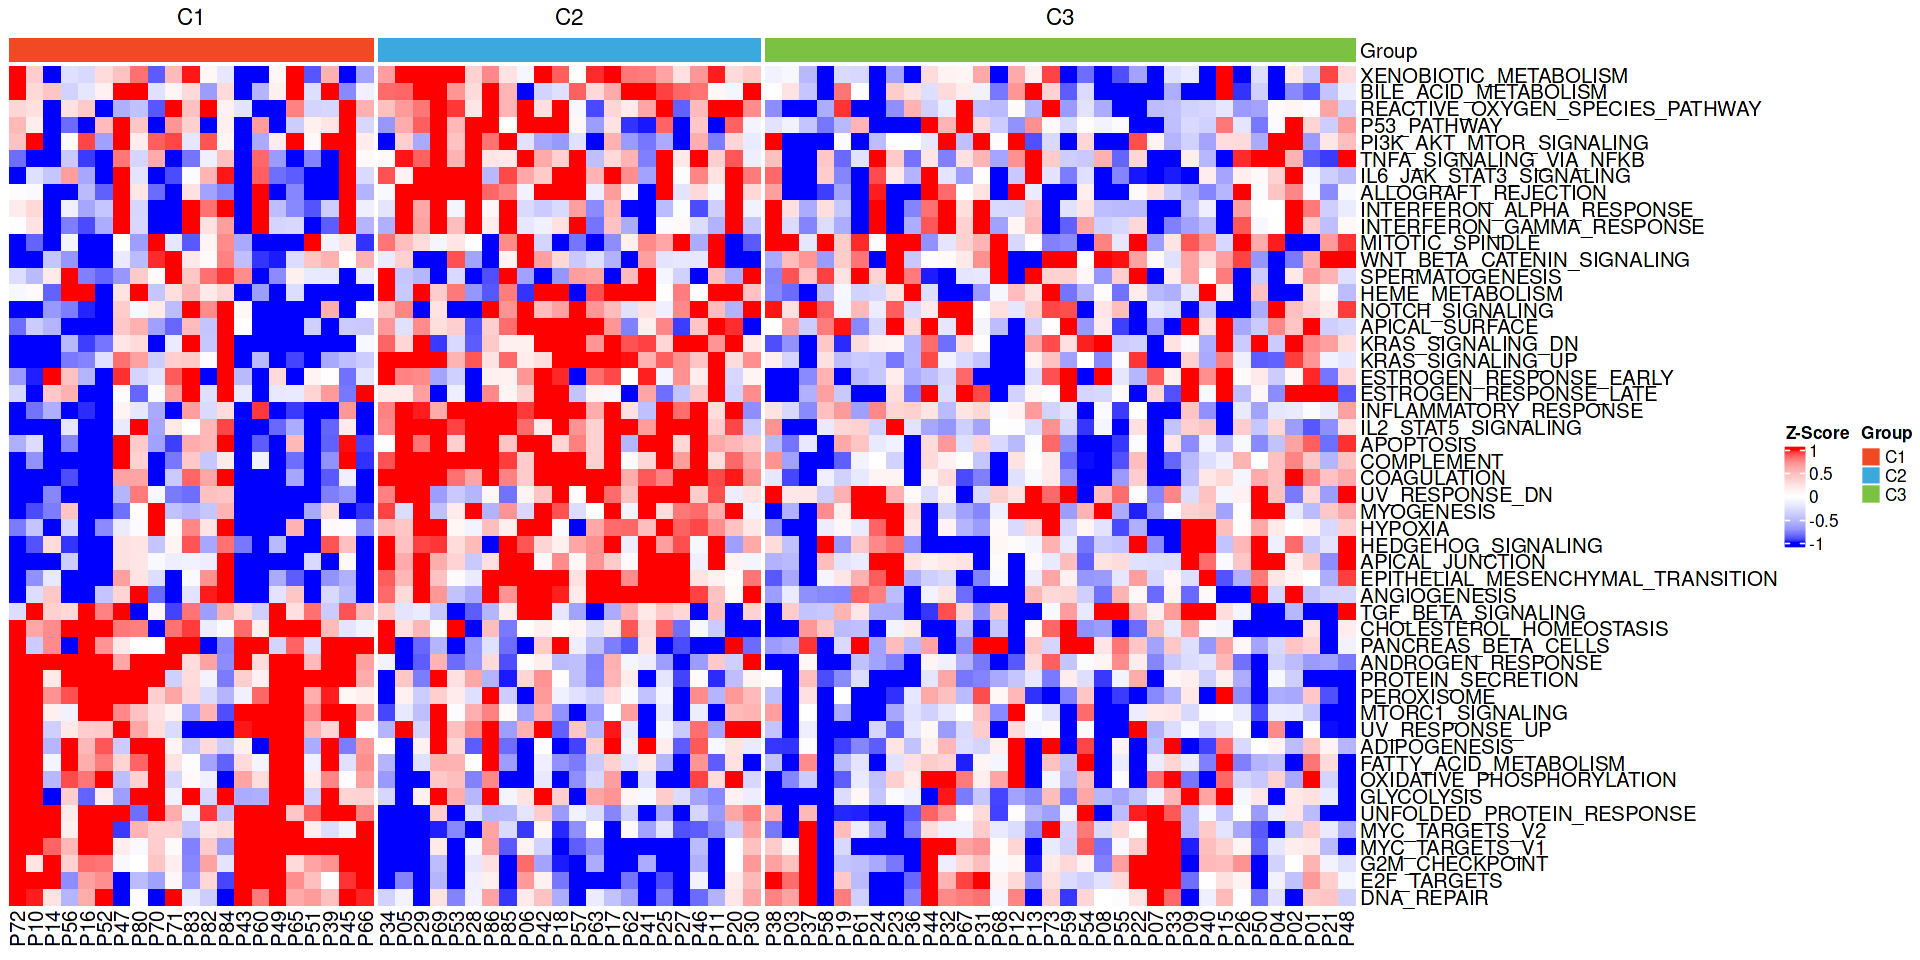

In [13]:
make.custom(16,8)
r = yplot_heatmap(mat = the_mat
            , cluster_columns = FALSE
          , colData = colData
          , annotation_colors = COL_ANNO_3G
          , color = COL_HEATMAP_1_F
          , by_group = TRUE
          , show_row_dend = FALSE
          , show_column_dend = FALSE
          , cluster_column_slices=FALSE
        )
r$gg

In [14]:
r$gg %>% ysave('fig.2A','prt.gsea.heatmap',outputdir = OUTPUTROOT)
the_mat %>% as.data.frame %>% ysave('fig.2A','prt.gsea.heatmap',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 08:34:19 ]  write 1 pdf at report_c3/fig.2A_prt.gsea.heatmap.pdf"
[1] "[ 2026-08-03 08:34:19 ]  write 1 xlsx at report_c3/fig.2A_prt.gsea.heatmap.xlsx"


## fig 2B Protein violin

In [15]:
p.hm = db.importing('export_c3/data_prt_hm_ssgsea.dfx', row.names = 1) %>% as.matrix
r.hm = db.importing('export_c3/data_rna_hm_ssgsea.dfx', row.names = 1) %>% as.matrix
rownames(p.hm) = rownames(p.hm) %>% str_sub(10)
rownames(r.hm) = rownames(r.hm) %>% str_sub(10)
p.hm = p.hm[rownames(r.hm), ]
r.hm

[1] "[ 2026-08-03 08:34:19 ]  read [ data_prt_hm_ssgsea.dfx ] as ' data_prt_hm_ssgsea ' from >  export_c3"
[1] "[ 2026-08-03 08:34:19 ]  read [ data_rna_hm_ssgsea.dfx ] as ' data_rna_hm_ssgsea ' from >  export_c3"


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
ADIPOGENESIS,0.5352774,0.5298981,0.5090610,0.5184800,0.5354779,0.5211951,0.5200553,0.5073797,0.5289627,0.5582152,0.5324584,0.5302997,0.5183914,0.51410397,0.5143569,⋯,0.5254624,0.5130609,0.4998273,0.4625052,0.5193511,0.5206493,0.4965634,0.4308143,0.5320755,0.5081452,0.5211257,0.5148786,0.5433077,0.5405400,0.5261268
ALLOGRAFT_REJECTION,0.2326303,0.2503244,0.2384866,0.2825841,0.3168723,0.2822995,0.2747259,0.2296043,0.2328125,0.3181382,0.2601588,0.2502184,0.2727498,0.04778801,0.1427947,⋯,0.2204546,0.2065525,0.2156567,0.2980156,0.2005738,0.1740938,0.2306263,0.2949878,0.2336081,0.2375681,0.2177265,0.2871917,0.2306788,0.2579551,0.2704492
ANDROGEN_RESPONSE,0.5890574,0.6126761,0.5148489,0.5700519,0.5536163,0.5677683,0.5944377,0.5979734,0.6070380,0.7073756,0.5689844,0.6164334,0.6692758,0.72334810,0.6111820,⋯,0.7484304,0.6312496,0.5363920,0.5940777,0.5749998,0.6039792,0.5328191,0.6213465,0.6321663,0.5836034,0.6735937,0.6847962,0.6602788,0.5895512,0.6068284
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
UV_RESPONSE_UP,0.3889393,0.3875211,0.3605759,0.3843370,0.4172113,0.3863432,0.3747113,0.3459818,0.3616664,0.4222272,0.3638295,0.3642286,0.3379974,0.3571061,0.3458448,⋯,0.3622854,0.3380766,0.3625837,0.3361088,0.3381536,0.3487323,0.3285762,0.3265504,0.3494795,0.3660530,0.3562501,0.3646824,0.3879374,0.4221292,0.3636105
WNT_BETA_CATENIN_SIGNALING,0.3893363,0.3750230,0.3840608,0.3899763,0.3702702,0.3878891,0.3967736,0.3442367,0.3888042,0.3496347,0.3902817,0.3824606,0.3632964,0.3645220,0.3480831,⋯,0.2465279,0.3680431,0.3721914,0.3372922,0.3465350,0.3492327,0.3059446,0.3326672,0.3170848,0.3717694,0.3257180,0.3370086,0.3585513,0.4001003,0.3304575
XENOBIOTIC_METABOLISM,0.3169911,0.3224968,0.3086505,0.3143726,0.3269857,0.3266780,0.2872466,0.3062376,0.3075108,0.3404812,0.3146023,0.3164913,0.3126442,0.2739694,0.2948532,⋯,0.2980902,0.2935568,0.2857357,0.2476658,0.2976162,0.2888410,0.2839699,0.2574565,0.3014670,0.3214422,0.3084378,0.2882905,0.3213407,0.3321165,0.3316892


In [16]:
glx = db.importing('export_c3/wes_glx.dfx') %>% rename(tsb = Tumor_Sample_Barcode, Group = Clin_classification)
glx

[1] "[ 2026-08-03 08:34:19 ]  read [ wes_glx.dfx ] as ' wes_glx ' from >  export_c3"


tsb,Group
<chr>,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P78,pCR
P76,pCR
P79,pCR


In [17]:
todo = list(Protein=p.hm %>% as.data.frame, RNAseq=r.hm %>% as.data.frame)


In [18]:
res = list()
# PLOT all
for (omic in names(todo)){
    res[[omic]] = list()
    mat =  todo[[omic]] %>% rownames_to_column('Pathway') 
    df = mat %>% 
        pivot_longer(-Pathway, names_to = 'tsb', values_to = "Activity") %>% 
        left_join(glx, by = 'tsb') %>%
        filter(Group != 'pCR')
    res[[omic]]$df = df
    stat = df %>% group_by(Pathway) %>% 
                            rstatix::t_test(Activity ~ Group) %>% 
                            rstatix::add_significance(p.col = 'p') %>% 
                            rstatix::p_format(p.fmt = p)
    res[[omic]]$stat = stat
    make.custom(18,30)
    gg = df %>% ggplot(aes(x = Group, y = Activity)) +
        geom_violin(aes(fill = Group),color=NA, alpha = 0.5) +
        ggbeeswarm::geom_beeswarm(aes(color = Group)) +
        facet_wrap(~Pathway, scales = 'free', ncol=6) +
        stat_summary(fun = mean, geom = "point", color= 'black', shape = 3, size = 5, stroke = 1) +
        ggpubr::stat_pwc(method = 't.test') +
        theme_pc() + 
        scale_fill_manual(values =  COL_GROUP3, breaks = names(COL_GROUP3)) +
        scale_color_manual(values =  COL_GROUP3, breaks = names(COL_GROUP3)) +
        ggtitle(omic) +
        ylab("Activity")
    res[[omic]]$gg.all = gg
    
    stat
        
}

In [19]:
## PLOT significant
sel = c('ANDROGEN_RESPONSE','MYC_TARGETS_V1', 'E2F_TARGETS','FATTY_ACID_METABOLISM')
for (omic in names(todo)){
    df = res[[omic]]$df
    p = res[[omic]]$stat %>% filter(p < 0.05) %>% group_by(Pathway) %>% summarise(n = n()) %>% filter(n > 1) %>% pull(Pathway)
    p = intersect(sel, p)
    gg2 = df %>%filter(Pathway %in% !!p) %>% 
        ggplot(aes(x = Group, y = Activity)) +
            geom_violin(aes(fill = Group),color=NA, alpha = 0.5, trim = FALSE) +
            geom_jitter(aes(color = Group), width = 0.25) +
            facet_wrap(~Pathway, scales = 'free', ncol=6) +
            stat_summary(fun = mean, geom = "point", color= 'black', shape = 3, size = 5, stroke = 1) +
            ggpubr::stat_pwc(method = 't.test') +
            theme_pc() + 
            scale_fill_manual(values =  COL_GROUP3, breaks = names(COL_GROUP3)) +
            scale_color_manual(values =  COL_GROUP3, breaks = names(COL_GROUP3)) +
            ggtitle(paste(omic, '2sig')) +
            ylab("Activity")
    res[[omic]]$gg.2sig = gg2
    res[[omic]]$df.2sig = df %>% filter(Pathway %in% !!p)
    res[[omic]]$cnt.2sig = length(p)
}



[1] "[ 2026-08-03 08:34:28 ]  write 1 pdf at report_c3/fig.2B.S4H.S4I_gsea_score.pdf"
[1] "[ 2026-08-03 08:34:28 ]  write 1 xlsx at report_c3/fig.2B.S4H.S4I_gsea_score.xlsx"


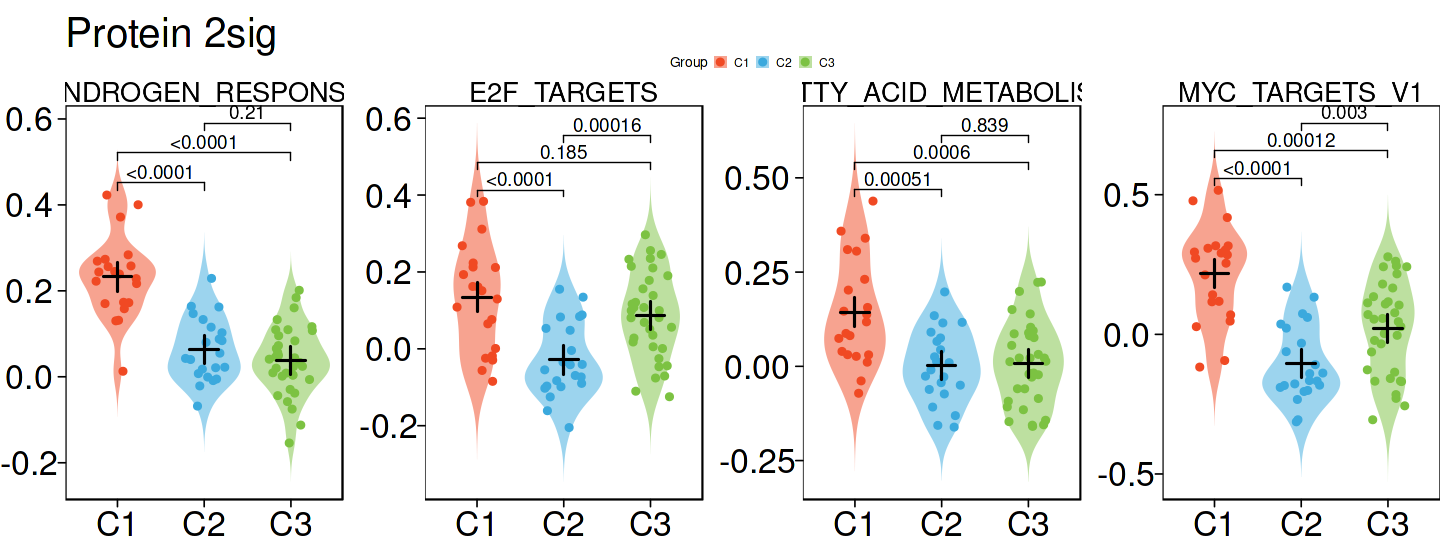

In [20]:
## fig.2B fig.S4H fig.S4I

sel = '2sig'
omic= 'Protein'
make.custom(3*ceiling(res[[omic]][[paste0('cnt.',sel)]] %% 6), ceiling(res[[omic]][[paste0('cnt.',sel)]] / 6) * 3.5+1)
res[[omic]][[paste0('gg.',sel)]]

res[[omic]][[paste0('gg.',sel)]] %>% ysave('fig.2B.S4H.S4I', 'gsea_score' ,outputdir = OUTPUTROOT)
res[[omic]][['df.2sig']] %>% ysave('fig.2B.S4H.S4I', 'gsea_score' ,outputdir = OUTPUTROOT)

In [21]:
# sel = '2sig'
# omic= 'RNAseq'
# make.custom(3*ceiling(res[[omic]][[paste0('cnt.',sel)]] %% 6), ceiling(res[[omic]][[paste0('cnt.',sel)]] / 6) * 3.5+1)
# res[[omic]][[paste0('gg.',sel)]]

## fig 2C S4G S4H S4I gsea

In [20]:
res.deg = readRDS('export_c3/fig2_deg_dap.RDS')
res.deg %>% names

[1] "RNAseq"  "Protein"

In [21]:
res.deg$Protein %>% names

[1] "C1" "C2" "C3"

In [22]:
outlist = res.deg %>% purrr::imap(function(degs, omic){
    print(omic)
    x = degs %>% purrr::map(function(obj){
        obj$deg
    })
    names(x) = paste(omic,names(x),sep='_')
    x
}) %>% purrr::reduce(.f = c)
names(outlist)

[1] "RNAseq"
[1] "Protein"


[1] "RNAseq_C1"  "RNAseq_C2"  "RNAseq_C3"  "Protein_C1" "Protein_C2"
[6] "Protein_C3"

In [23]:
outlist %>% ysave('fig.2C','data_DEG_DAP',outputdir = file.path(OUTPUTROOT,'gsea_input'))

[1] "[ 2026-08-29 07:34:27 ]  write 1 xlsx at report_c3/gsea_input/fig.2C_data_DEG_DAP.xlsx"


**this figure is plot by Python script, see PY_ANALYSIS_Fig2_Fig3.ipynb**

### fig 2C

In [24]:


display_html('
  <div>
    <iframe src="./report_c3/gsea_report/rna_c1/Nature_Med_2016.prerank.pdf" 
            width="800" height="600" style="border:none;">
    </iframe>
    <iframe src="./report_c3/gsea_report/rna_c1/Asangani_AR_signature.prerank.pdf" 
            width="800" height="600" style="border:none;">
    </iframe>
  </div>
')

### fig S4G

In [28]:

display_html('
  <div>
    <iframe src="./report_c3/gsea_report/rna_c1_hm/HALLMARK_ANDROGEN_RESPONSE.prerank.pdf" 
            width="800" height="600" style="border:none;">
    </iframe>
    <iframe src="./report_c3/gsea_report/rna_c1_hm/HALLMARK_MYC_TARGETS_V1.prerank.pdf" 
            width="800" height="600" style="border:none;">
    </iframe>
  </div>
')

### fig S4H

In [29]:

display_html('
  <div>
    <iframe src="./report_c3/gsea_report/rna_c1_hm/HALLMARK_E2F_TARGETS.prerank.pdf" 
            width="800" height="600" style="border:none;">
    </iframe>
  </div>
')


### fig S4I

In [30]:

display_html('
  <div>
    <iframe src="./report_c3/gsea_report/rna_c1_hm/HALLMARK_FATTY_ACID_METABOLISM.prerank.pdf" 
            width="800" height="600" style="border:none;">
    </iframe>
  </div>
')


## fig 2D AR heatmap

In [25]:
ar = db.importing('external_data/AR调控轴基因总结.xlsx',sheet_name=1) #%>% 
    #distinct() %>% pull(genes)
ar_v = rlang::flatten_chr(ar) %>% na.omit %>% unique()

ar

[1] "[ 2026-08-29 07:37:15 ]  read [ AR调控轴基因总结.xlsx ] as ' AR调控轴基因总结 ' from >  external_data"


Warning message:
“`flatten_chr()` is deprecated as of rlang 1.1.0.
ℹ Please use `purrr::list_flatten()` and/or `purrr::list_c()`.
This warning is displayed once every 8 hours.”
Warning message:
“Outer names are only allowed for unnamed scalar atomic inputs”


,PNAS_2002,Cancer_Cell_2006,JCO_2008,EU_2015,Asangani_AR_signature,Cell_2015,Nature_Med_2016,CCR_2019
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,HPGD,FKBP5,KLK2,STEAP1,ABCC4,KLK3,MPHOSPH9,KLK3
2,PPAP2A,KLK2,ORM1,STEAP2,ABHD2,KLK2,ADAM7,KLK2
3,SCD,ZBTB10,C1orf116,TMPRESS2,ACSL3,PMEPA1,FOLH1,STEAP1
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
523,NA,NA,CTBP1,NA,NA,NA,NA,NA
524,NA,NA,VGLL4,NA,NA,NA,NA,NA
525,NA,NA,ZNG1F,NA,NA,NA,NA,NA


In [26]:
res.deg = readRDS('export_c3/fig2_deg_dap.RDS')

In [27]:
glx = db.importing('wes_glx',outputdir = 'export_c3/') %>% 
    rename(tsb = Tumor_Sample_Barcode, Group=Clin_classification)
colData = glx %>% column_to_rownames('tsb')
glx

[1] "[ 2026-08-29 07:37:18 ]  read [ wes_glx.dfx ] as ' wes_glx ' from >  export_c3"


tsb,Group
<chr>,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P78,pCR
P76,pCR
P79,pCR


In [28]:
# ## generate matp
# matp = db.importing('export_by2_86_pCR_nonpCR/prt_ori_7717.dfx') %>%
#     mutate(Protein_ID = V1 %>% str_split(fixed('_'),simplify = TRUE) %>% .[,1],.before = V1)
# # 把Protein_ID 转换为symbol
# protein_name = AnnotationDbi::select(org.Hs.eg.db, keys = matp$Protein_ID, columns = c("SYMBOL", "UNIPROT"), keytype = "UNIPROT") %>%
#     filter(!is.na(SYMBOL)) %>% dplyr::rename(Protein_ID = UNIPROT)

# matp = matp %>% right_join(protein_name, by='Protein_ID') %>%  ungroup() %>%
#     dplyr::select(-c(Protein_ID,V1)) 
# # 合并同SYMBOL的行,取mean

# G = c()
# matp = matp %>%group_by(SYMBOL) %>% group_map(.f = function(df, g){
#         g = as.character(g)
#         G <<- c(G,g)
#         df %>% apply(2,mean)
#     }) %>% bind_rows() %>% mutate(SYMBOL=!!G) %>% column_to_rownames("SYMBOL")
# matp


In [29]:
matp = db.importing('export_by2_86_pCR_nonpCR/prt_x_7346.dfx',row.names=1) %>% as.matrix
matp

[1] "[ 2026-08-29 07:37:20 ]  read [ prt_x_7346.dfx ] as ' prt_x_7346 ' from >  export_by2_86_pCR_nonpCR"


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
A1BG,0.287177300,0.2939069,-0.09063044,0.002907455,0.1872858,0.0786567,-0.2096906,0.09307132,-0.18867919,-0.1763565,0.08286262,0.17281162,-0.12209438,-0.1674641,0.10716068,⋯,-0.4503532,0.05239038,0.2241172,-0.5238935,-0.2655707,0.09135753,-0.006072252,-0.05176097,0.28097609,0.027872053,0.254332178,-0.06081656,0.19313675,0.03145473,0.2607692
A2M,0.002229604,0.4094927,-0.19584423,0.030336738,0.4629664,0.1099765,-0.3369603,-0.29084987,-0.25064389,-0.3843764,-0.14070869,0.21562212,0.07690258,-0.7912119,0.07218912,⋯,-0.7344648,0.30101487,-0.1285149,-0.4528443,-0.3526046,-0.13174759,0.351870409,-0.14086773,0.47887702,0.195851290,-0.006584813,-0.26987836,0.08291092,-0.04138966,0.3934887
NAT1,-0.026871998,0.1430298,0.06954354,0.290496090,-0.2472083,-0.2937601,-0.3611383,0.09370171,0.04050201,0.9339046,-0.03848733,0.08026074,0.12363854,0.1643513,0.17016346,⋯,-0.4062785,-0.07808169,-0.1460621,0.0981409,-0.0509333,0.03641082,0.026474850,-0.12458426,-0.08672934,0.003876838,-0.003910516,0.14163022,0.11802263,-0.03668439,-0.3778016
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
MMP24OS,-0.621264397,-0.04444896,0.2691024,-0.76502545,-0.12274365,0.2520254,0.21506206,0.0229764,-0.09789900,-0.09939606,0.3709879,-0.316303895,0.03415481,0.35936385,-0.39227925,⋯,0.01028101,0.13706324,0.2377145,-0.3052630,-1.04025035,0.15048669,-0.08201886,0.3497500,-0.10943026,0.3785018,0.07455987,-0.006554967,0.04642637,0.009285301,-0.160911045
PIGBOS1,-0.049884599,-0.11042890,-0.2499968,0.12671735,0.73116698,0.4558270,-0.09163530,-0.0586082,0.23340032,0.08074380,0.1898183,-0.089041760,0.27521537,0.02440433,-0.06805847,⋯,-0.10079324,1.40279920,0.2661333,-0.3193722,-0.28851378,0.07083822,-0.29635793,0.4263346,1.11805949,0.0000741,0.27900442,0.050621964,0.25783404,0.202667933,0.265910471
C11orf98,0.004816554,0.17542232,0.1996632,0.05945041,-0.01073928,0.5687702,0.08974135,0.3175692,-0.02536341,0.32200949,0.2234118,-0.008669873,0.06901888,0.18103901,-0.05487164,⋯,0.48660996,0.02520704,0.1621864,-0.1466143,0.01227122,0.36640957,-0.31123749,0.3366186,0.04104325,0.2597731,0.07265562,0.150302465,0.26595657,0.788633701,0.007909265


In [30]:
manual_sel = read.table('external_data/初步挑选ARGs绘制C1-C3热图.txt', 
                        header=0) %>% 
    rename(symbol=V1)
manual_sel

symbol
<chr>
C1orf116
TMPRSS2
MCM7
⋮
ACAT2
AKAP1
GOLM1


In [36]:
deg = res.deg$Protein$C1$deg
x.ar.deg = deg$symbol %>% intersect(ar_v)
length(x.ar.deg)
x = intersect(x.ar.deg, rownames(matp)) %>% intersect(manual_sel$symbol)
length(x)

mat_main = matp[x, glx$tsb] %>% yscale_rows()
mat_main

[1] 319

[1] 30

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P50,P04,P02,P01,P21,P48,P77,P35,P81,P74,P75,P64,P78,P76,P79
STEAP1,2.146160,1.0245273,-0.01904504,3.462174,3.2981084,2.7225377,-0.1304853,-0.2531458,0.3541241,1.5534256,0.1888443,0.7112928,0.05268681,1.3171878,1.0295952,⋯,-0.6403423,-0.5711546,-0.2361343,-0.8206550,-0.5312147,0.02338118,0.1879738,0.3857190,-0.3199254,-1.0631554,-0.3291249,0.1655388,-0.6217038,-0.93939417,0.3845785
FOLH1,1.634188,1.7696235,0.36144608,4.117163,3.5802480,1.8445409,0.3602797,-0.9151992,2.9122620,0.6404412,0.7236068,0.6187491,0.65394963,-0.7574701,-0.9813205,⋯,0.2267910,-0.8971645,-0.4790731,-0.7142574,-0.4896126,-0.57332235,-0.4676096,-0.6876498,-0.3802898,-0.3601596,-0.9334710,-0.3668801,-0.6709493,-0.95482259,-0.4901177
ACAT2,3.352107,-0.7455252,-1.52126953,1.441770,0.5323526,0.9570392,2.3068307,-1.3565612,0.3894017,0.1825417,-0.2259201,1.0751917,-0.14901572,2.1881092,0.6247693,⋯,-0.6720293,-0.6566522,0.1067140,-0.2515080,-0.5883717,-0.55408671,-0.1956578,0.2229222,0.0361544,-0.3440710,0.4294422,0.2158606,0.1161494,-0.01675641,0.1972605
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
MCM6,3.766139,2.6996746,0.0540786,-1.211218,-0.7533519,1.454131,-0.3551269,0.17792822,-1.2891401,-0.59344738,0.2718619675,0.04045553,-0.7043223,-0.8771148,3.33226988,⋯,-1.3298675,0.5118812,-0.1579048,0.11525681,0.3525768,0.2414703,-0.85438313,-0.2842648,-0.1540422,0.3190167,0.2179518,0.4246030,0.7633941,0.6507314,-0.4171005
OCLN,1.010257,0.5650645,2.0483208,2.699248,-0.5615884,1.974267,-0.8275373,-0.03608627,-0.5756312,-0.07446452,-1.0525023933,-0.55646285,-0.9518640,2.5187921,0.06704096,⋯,-0.3425254,-1.3689867,-0.9153431,0.50331785,-0.6053765,0.3879063,1.56147442,-0.3990067,0.1405711,-1.3374041,0.4449608,2.2288888,0.7523123,-0.1749373,1.0629759
MCM7,1.859921,1.3191511,1.6590122,-1.357128,1.5936032,1.385031,-0.3120063,-1.86556543,-0.6803578,-1.09723166,0.0004894388,0.46099847,-0.9759264,-0.7906694,4.82874839,⋯,0.5746117,0.5263475,-0.2625286,0.09669536,0.2984256,-0.2992497,0.01411856,-0.7411318,0.2102877,0.7694128,-0.6163977,0.6314503,0.4304239,2.1925891,-0.3829056


In [37]:
i2 = db.importing('external_data/Figure_1_heatmap_clustering_noval/02-2015 Cell.xlsx') %>% pull('AR.score')
sel_genes = list(i2=i2 %>% str_replace(fixed('−'),'-'))
sel_genes

[1] "[ 2026-08-24 01:09:26 ]  read [ 02-2015 Cell.xlsx ] as ' 02-2015 Cell ' from >  external_data/Figure_1_heatmap_clustering_noval"


$i2
 [1] "KLK3"     "KLK2"     "PMEPA1"   "ABCC4"    "NKX3-1"   "C1orf116"
 [7] "FKBP5"    "ACSL3"    "ZBTB10"   "HERC3"    "PTGER4"   "MPHOSPH9"
[13] "EAF2"     "MED28"    "NNMT"     "MAF"      "GNMT"     "CENPN"   
[19] "ELL2"     "TMPRSS2"

In [38]:
length(sel_genes$i2)

[1] 20

In [39]:
tpm = db.importing('export_by2_86_pCR_nonpCR/rna_tpm.dfx',row.names=1)
tpm = tpm %>% yscale_rows()
rn = rownames(tpm)
tpm

[1] "[ 2026-08-24 01:09:28 ]  read [ rna_tpm.dfx ] as ' rna_tpm ' from >  export_by2_86_pCR_nonpCR"


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A1BG,-0.4855886,0.5014804,2.7236634,0.1730071,0.1481480,-1.2353842,2.1735931,-0.6131654,0.4585166,-1.3504707,-1.2955723,2.025372,0.2737723,-0.1401712,-0.1745957,⋯,-1.1955454,1.1312233,0.8551604,-1.020626,0.8189031,-1.0352110,0.4058479,3.19567227,-1.7607185,0.05567803,-1.14621627,-1.05850520,-0.7985181,0.1127389,-0.93181036
A1CF,-0.1161383,-0.1823657,-0.2452381,-0.1968692,-0.1789227,-0.1722361,-0.2377828,-0.1278122,-0.2452381,-0.2366867,-0.1385853,-0.203148,-0.2452381,0.2276734,-0.1129908,⋯,-0.2295305,-0.2280150,-0.2116833,-0.129537,-0.1914673,-0.1923083,-0.1850236,-0.09600797,-0.2452381,-0.19791089,-0.23883362,-0.09886569,-0.2452381,-0.1964241,-0.08973499
A2M,-0.8730303,0.3104629,2.3914537,2.4753550,0.5793191,0.1008175,-0.6621469,-0.3186986,-0.7051612,-0.3804044,0.6087660,0.268754,-0.3445897,-1.5716794,-0.6795127,⋯,-1.4295698,-0.6654458,-0.2920761,-1.097248,1.0924215,-1.0559613,1.5870857,-1.29197483,-0.2015407,-0.11336386,-0.03418905,-1.20422236,-0.5303389,-0.7305449,-0.44726158
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZYX,-1.0123392,0.04026234,-0.09850808,0.8720102,1.32916531,1.3211222,0.4946929,-0.31008502,0.4001928,0.4993866,0.4150131,-0.1948805,-0.1298230,-1.043271,-1.1241311,⋯,-2.2113850,-0.1938584,0.1050543,-1.1487586,-0.8224766,0.06592301,-1.1935408,-0.8991824,-1.8991565,-0.1392697,-0.4115419,-0.6002370,-0.4391260,1.6363605,-0.8057879
ZZEF1,-0.5724327,0.60774865,1.83335587,0.6047182,1.43551514,0.7697171,0.6963130,-0.15816024,0.5777250,-0.2706896,0.5806450,1.4251004,0.6699380,-1.511106,-0.6687868,⋯,-2.5282614,0.2666425,0.2187061,0.8991809,-0.5532873,0.77749677,-0.7431488,2.1665144,-1.6645030,1.1634290,-0.3402452,0.2673713,0.6205789,-0.3822241,-0.7874676
ZZZ3,-0.5331847,-0.41294625,0.05077819,-0.4361927,0.08487503,-0.2881117,-0.4930367,-0.01721653,-0.1173904,-1.4586038,-0.4864049,-0.6870824,-0.5983299,-0.381501,0.1022733,⋯,-0.0945602,0.4206441,1.6161125,4.2106199,1.7494004,1.32875071,2.0003406,3.9431107,0.2605589,1.6685745,0.8732197,1.4954999,0.5686218,-0.4284372,1.2720705


In [40]:
## AR score is calculated the same as the 'AR output score analysis' section in the reference
## Cancer Genome Atlas Research N. The Molecular Taxonomy of Primary Prostate Cancer. Cell 2015; 163 (4): 1011–1025.

res = list()
for (s in 2){
    iname = paste0("i",s)
    i = sel_genes[[iname]]
    x = rn %>% intersect(i)
    mat_tpm = tpm[x,]
    zscore_mat = t(apply(mat_tpm, 1, function(x) {
        (x - mean(x, na.rm = TRUE)) / sd(x, na.rm = TRUE)
    }))
    index = zscore_mat %>% apply(2, sum)
    res[[iname]] = index
}
res = data.frame(res) %>% t %>% as.data.frame()
rownames(res) = c('AR activity Score, TCGA')
res = res %>% yscale_rows() %>% as.matrix()
res = res[, rownames(colData), drop=FALSE]
# res = res %>% as.matrix()
ar_activity_score = res

ar_activity_score

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P50,P04,P02,P01,P21,P48,P77,P35,P81,P74,P75,P64,P78,P76,P79
"AR activity Score, TCGA",4.670825,3.062196,2.633203,2.183024,2.830105,1.825733,0.3528234,-0.3028079,0.1139356,0.6087798,1.26536,1.127763,0.1871899,0.3428313,1.624014,⋯,-1.24591,-0.08423045,-0.2830463,-1.018158,-0.9045481,-0.5429852,-0.1504807,-0.5523492,-0.2411211,-0.6537305,0.328599,-0.2626837,-0.3111341,-0.475367,1.105022


In [41]:
ar_activity_score %>% ydumpto('fig2_ar_activity_score.txt', outputdir = INPUTROOT)


[1] "[ 2026-08-24 01:10:18 ]  write 1 < txt > at export_c3/fig2_ar_activity_score.txt"


[1] "export_c3/fig2_ar_activity_score.txt"

In [42]:
nonpcr = glx %>% filter(Group!='pCR')
ar_activity_score_77 = ar_activity_score[,nonpcr$tsb,drop=FALSE]
colData77 = colData[nonpcr$tsb,,drop=FALSE]
ar_activity_score_77

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
"AR activity Score, TCGA",4.670825,3.062196,2.633203,2.183024,2.830105,1.825733,0.3528234,-0.3028079,0.1139356,0.6087798,1.26536,1.127763,0.1871899,0.3428313,1.624014,⋯,-0.3867039,0.7338748,-0.4713913,-0.2949954,-0.7722856,-0.2227715,-0.6016549,-0.5454849,-0.3431062,-1.24591,-0.08423045,-0.2830463,-1.018158,-0.9045481,-0.5429852


In [43]:
colData77

,Group
,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P01,C3
P21,C3
P48,C3


In [44]:
main_plt = ComplexHeatmap::Heatmap(
    ar_activity_score_77
    , show_column_names = TRUE
    , column_title_gp = gpar(fontsize = 6)
    , show_row_dend = FALSE

    #                 , column_title = paste('Protein',do,'GSEA')
    , rect_gp = gpar(col = COL_HEATMAP_BORDER, lwd=0.5)
    , name = "Protein Abudance"
    , column_names_gp = gpar(fontsize=8)
    , row_names_gp = gpar(fontsize=8)
#     , top_annotation = HeatmapAnnotation(Group = colData$Clin_classification, col = list(Group=COL_ANNO$Clin_classification))
    , column_split = colData77$Group 
    , cluster_columns = FALSE
    , cluster_rows = TRUE
    , col = COL_HEATMAP_2_F
    #                 , col = COL_HEATMAP_0_F
    #                 , column_split = anno$Group
    #                 , column_labels = anno$Cluster
    , heatmap_legend_param = list(direction = "horizontal")

)


In [45]:
make.custom(8, 4)
top_plt = ComplexHeatmap::Heatmap(matrix = mat_main[,colData77%>%rownames]
            , row_title = 'AR target genes'
              , show_column_names = TRUE
              , column_title_gp = gpar(fontsize = 6)
                , show_row_dend = FALSE
              
#                 , column_title = paste('Protein',do,'GSEA')
                , rect_gp = gpar(col = COL_HEATMAP_BORDER, lwd=0.5)
                , name = "Protein Abudance"
                , column_names_gp = gpar(fontsize=8)
                , row_names_gp = gpar(fontsize=8)
                , top_annotation = HeatmapAnnotation(Group = colData77$Group, col = list(Group=COL_ANNO$Clin_classification))
                , column_split = colData77$Group
                , cluster_columns = FALSE
                , cluster_rows = TRUE
                , col = COL_HEATMAP_2_F
#                 , col = COL_HEATMAP_0_F
#                 , column_split = anno$Group
#                 , column_labels = anno$Cluster
               , heatmap_legend_param = list(direction = "horizontal")
#               , width = unit(1, "inch")
            )



Warning message:
“Heatmap/annotation names are duplicated: Protein Abudance”


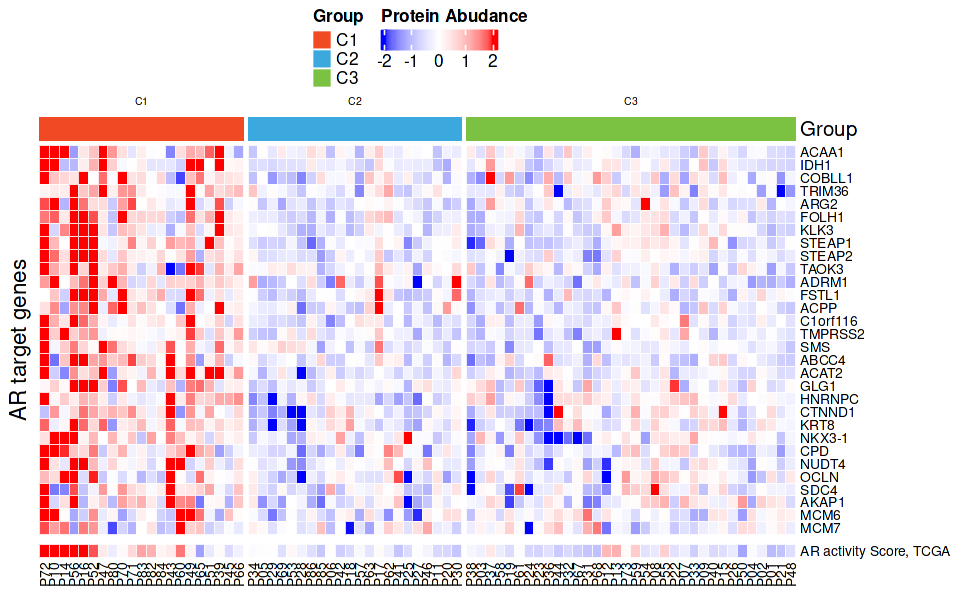

In [46]:
make.custom(8,5)
plt = top_plt %v% main_plt 
draw(plt, heatmap_legend_side = "top")


In [48]:
make.custom(8,5)
plt %>% ysave('fig.2D','AR_target_gene',outputdir = OUTPUTROOT)
rbind(mat_main[,colData77%>%rownames], ar_activity_score_77) %>% as.data.frame %>% ysave('fig.2D','AR_target_gene',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 08:35:13 ]  write 1 pdf at report_c3/fig.2D_AR_target_gene.pdf"
[1] "[ 2026-08-03 08:35:13 ]  write 1 xlsx at report_c3/fig.2D_AR_target_gene.xlsx"


## fig 2E AR barplot

In [49]:
# glx is loaded @ section 'fig 2D'
glx = db.importing('wes_glx',outputdir = 'export_c3/') %>% 
    rename(tsb = Tumor_Sample_Barcode, Group=Clin_classification)
glx

[1] "[ 2026-08-03 08:35:13 ]  read [ wes_glx.dfx ] as ' wes_glx ' from >  export_c3"


tsb,Group
<chr>,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P78,pCR
P76,pCR
P79,pCR


In [50]:
ar_activity_score = db.importing('export_c3/fig2_ar_activity_score.txt', row.names=1)
#threshold = 0.2

ar_act_score = ar_activity_score %>% t %>% 
    as.data.frame %>%
    rename(score=`AR activity Score, TCGA`) 

topN = nrow(ar_act_score) - ceiling(nrow(ar_act_score) * 0.75)
topN

high_tsb = ar_act_score %>% arrange(score) %>% tail(topN) %>% rownames()

ar_act_score = ar_act_score %>% 
        rownames_to_column('tsb') %>% 
        mutate(cat=ifelse(tsb %in% high_tsb, 'High','Low'), 
        cat=factor(cat, levels = c('Low','High'))) %>%
        left_join(glx, by = 'tsb')
ar_act_score

statistics = ar_act_score %>%
  group_by(Group, cat) %>%
  count() %>%
  group_by(Group) %>%
  mutate(pct = n / sum(n) * 100)
statistics


[1] "[ 2026-08-03 08:35:13 ]  read [ fig2_ar_activity_score.txt ] as ' fig.2D.ar_act_score ' from >  export_c3"


[1] 21

tsb,score,cat,Group
<chr>,<dbl>,<fct>,<chr>
P72,4.670825,High,C1
P10,3.062196,High,C1
P14,2.633203,High,C1
⋮,⋮,⋮,⋮
P78,-0.3111341,Low,pCR
P76,-0.4753670,Low,pCR
P79,1.1050224,High,pCR


Group,cat,n,pct
<chr>,<fct>,<int>,<dbl>
C1,Low,7,33.33333
C1,High,14,66.66667
C2,Low,22,100.00000
⋮,⋮,⋮,⋮
C3,High,5,14.70588
pCR,Low,7,77.77778
pCR,High,2,22.22222


In [51]:
statistics %>% group_by(cat) %>% summarise(n=sum(n))

cat,n
<fct>,<int>
Low,65
High,21


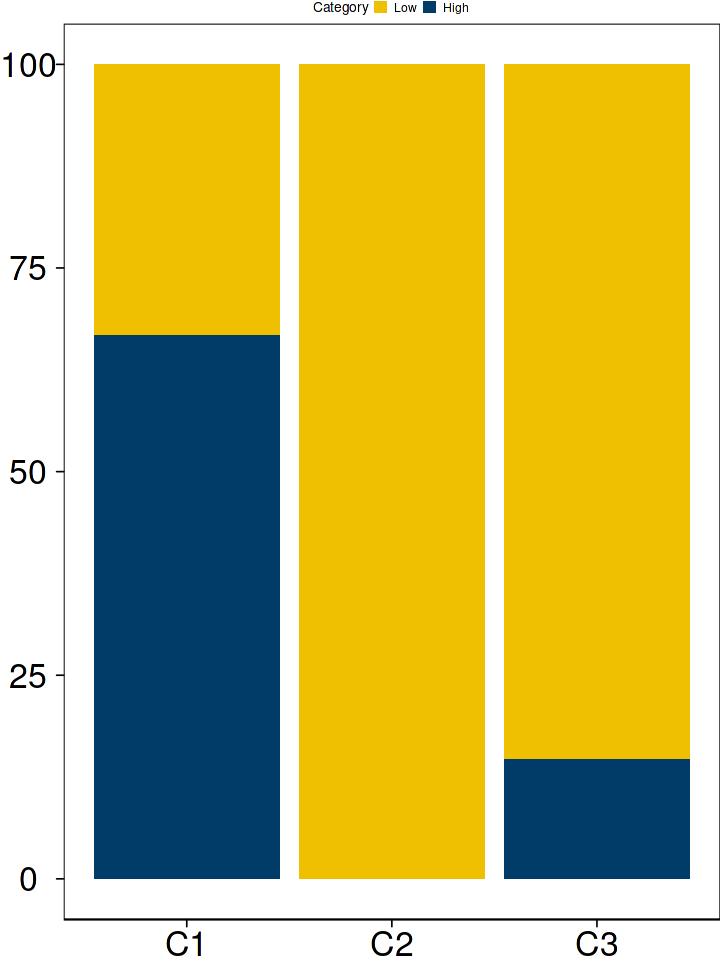

In [52]:
make.tall()
gg = statistics %>% filter(Group!='pCR') %>% 
    ggplot(aes(x=Group,y = pct, fill = cat))+ 
    geom_bar(stat = 'identity') +
#     geom_text(aes(label = paste0(round(pct, 1), "%")),
#             position = position_stack(vjust = 0.5), size = 3.5) +
    theme_pc() +
    scale_fill_manual(values = COL_AR) +
    labs(x = "Group", y = "Percentage (%)", fill = "Category")

gg

In [53]:
# ggplot(ar_act_score, aes(x=score, fill=Group))+geom_histogram()

In [54]:
gg %>% ysave('fig.2E.AR_acti_portion_bar',outputdir = OUTPUTROOT)
statistics %>% filter(Group!='pCR') %>% ysave('fig.2E.AR_acti_portion_bar',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 08:35:13 ]  write 1 pdf at report_c3/fig.2E.AR_acti_portion_bar.pdf"
[1] "[ 2026-08-03 08:35:13 ]  write 1 xlsx at report_c3/fig.2E.AR_acti_portion_bar.xlsx"


In [55]:
INPUTROOT

[1] "export_c3"

In [56]:

ar_act_score %>% ydumpto('fig2_ar_activity_group.dfx',outputdir = INPUTROOT)


[1] "[ 2026-08-03 08:35:13 ]  write 1 < dfx > at export_c3/fig2_ar_activity_group.dfx"


[1] "export_c3/fig2_ar_activity_group.dfx"

## fig 2F AR survplot

In [57]:
# glx is loaded @ section 'fig 2D'
glx = db.importing('wes_glx',outputdir = 'export_c3/') %>% 
    rename(tsb = Tumor_Sample_Barcode, Group=Clin_classification)
glx

[1] "[ 2026-08-03 08:35:13 ]  read [ wes_glx.dfx ] as ' wes_glx ' from >  export_c3"


tsb,Group
<chr>,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P78,pCR
P76,pCR
P79,pCR


In [58]:

load_os = function(){
#     glx = db.importing('export_c3/glx_86.dfx') %>% rename(Custom_Label = tsb )
    # NOTE: 该文件为上游产物(本项目代码中无生成 cell),需在生成处同时输出到 export_c3/ (供读取) 与 report_c3/ (结果副本)
    glx = db.importing('export_c3/fig1_subtype_predict_and_pca_data.xlsx') %>%
        rename(Custom_Label=X1)
       
#     glxv = db.importing('external_info/Proteomics52/washed/prt_glx.dfx') %>%mutate(Response = Group, Group = 'UC')
#     glxall = glx %>% 
#         select(Custom_Label, uid, Group, Response) %>%
#         mutate(source ='train86', .before = Group) %>%
#         mutate(Group = 'UC') %>%
#         rbind(glxv)
    clin2 = db.importing('external_data/Fig1_heatmap_clinical_pathological_information.txt')
    os = clin2 %>% select(Custom_Label
                        , BCR_status 
                        , BCR_month = `BCR-free.time`
                        , RGR_status = `Radiographic.recurrence`
                        , RGR_month = `Radiographic.recurrence-free.time`
                        ) %>%
        mutate(BCR_status = as.numeric(BCR_status)
               , BCR_month = as.numeric(BCR_month)
               , RGR_status = as.numeric(RGR_status)
               , RGR_month = as.numeric(RGR_month)
              ) %>% left_join(glx,by='Custom_Label')
    
    os %>% mutate(
        Set = ifelse(is.na(Set), ifelse(str_length(Custom_Label) == 3,'Train','Valid') ,Set)
#         , Group = ifelse(is.na(Group),'pCR', Group)
        , Cluster = ifelse(is.na(Cluster),'pCR', Cluster)
        , source = ifelse(Set=='Train','train86','valid52')
    ) %>% select(-x,-y)
}

do_stat_surv = function(data, symbol , omic_name, cutoff){
    fit = survival::survfit(survival::Surv(BCR_month, BCR_status) ~ Group, data = data)
    med = summary(fit)$table[,'median']
    
    diff_AB <- survival::survdiff(survival::Surv(BCR_month, BCR_status) ~ Group, data = data, rho = 0)
    s = list(names(diff_AB$n[1]), 
             med[[1]], med[[2]], 
             diff_AB$n[[1]], diff_AB$n[[2]],
             diff_AB$obs[1], diff_AB$obs[2], 
             diff_AB$pvalue, 
             symbol, omic_name, cutoff)
    names(s) = c('Group1st','med_LOW','med_HIGH','N_LOW','N_HIGH',
                 "ob_LOW",'ob_HIGH','pval',"symbol", 'omic','cutoff')
    data.frame(s)
}

In [59]:
ar_act_score = yload_dfx('export_c3/fig2_ar_activity_group.dfx')
ar_act_score

[1] "[ 2026-08-03 08:35:13 ]  read [ fig2_ar_activity_group.dfx ] as ' fig.2E.AR_activity ' from >  export_c3"


tsb,score,cat,Group
<chr>,<dbl>,<chr>,<chr>
P72,4.670825,High,C1
P10,3.062196,High,C1
P14,2.633203,High,C1
⋮,⋮,⋮,⋮
P78,-0.3111341,Low,pCR
P76,-0.4753670,Low,pCR
P79,1.1050224,High,pCR


In [60]:
# ar_act_score is generated by section 'fig 2E ...'
os = load_os()
data = os %>% rename(tsb=Custom_Label,Group.os=Group) %>%
    right_join(ar_act_score, by='tsb')
data

[1] "[ 2026-08-03 08:35:13 ]  read [ fig1_subtype_predict_and_pca_data.xlsx ] as ' fig1_subtype_predict_and_pca_data ' from >  export_c3"
[1] "[ 2026-08-03 08:35:13 ]  read [ Fig1_heatmap_clinical_pathological_information.txt ] as ' Fig1_heatmap_clinical_pathological_information ' from >  external_data"


tsb,BCR_status,BCR_month,RGR_status,RGR_month,Set,Group.os,Cluster,sel_organ,source,score,cat,Group
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
P01,0,35,0,35,Train,C3,C3,NA,train86,-1.0181582,Low,C3
P02,0,22,0,22,Train,C3,C3,NA,train86,-0.2830463,Low,C3
P03,0,27,0,27,Train,C3,C3,NA,train86,-0.2817504,Low,C3
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
P84,0,20,0,21,Train,C1,C1,NA,train86,0.1871899,High,C1
P85,1,7,0,22,Train,C2,C2,NA,train86,-0.8601089,Low,C2
P86,0,16,0,17,Train,C2,C2,NA,train86,-0.5393486,Low,C2


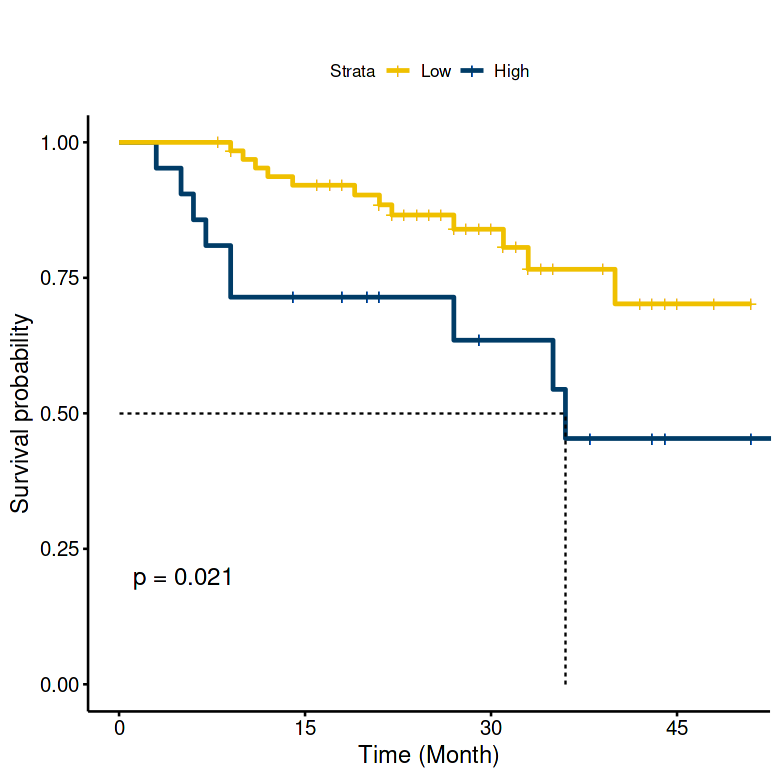

In [61]:
make.custom(6.5,6.5)
ti = ""
fit = survival::survfit(survival::Surv(RGR_month, RGR_status) ~ cat
                        , data = data)
fig = survminer::ggsurvplot(fit, data = data
#                                   , palette =  COL_Group3
                     ,risk.table = FALSE # Add risk table
                     ,pval = TRUE # Add p-value
                     ,conf.int = FALSE # Add confidence interval
#                      ,risk.table.col = "strata"
#                      ,test.for.trend = TRUE
                     ,surv.median.line = 'hv'
                    ,color = 'cat'
#                     , color = COL_ANNO_3G$Group3
                    ,break.x.by = 15
                     ,xlab = 'Time (Month)'
#                      ,xlim=c(0,90)
                    ,ti = paste(ti)
                    ) 
fig[[1]] = fig[[1]] + scale_color_manual(values=COL_AR, breaks = names(COL_AR))

fig

In [62]:
med = summary(fit)$table[,'median']
    
diff_AB <- survival::survdiff(survival::Surv(RGR_month, RGR_status) ~ cat, 
                              data = data, rho = 0)
diff_AB

Call:
survival::survdiff(formula = survival::Surv(RGR_month, RGR_status) ~ 
    cat, data = data, rho = 0)

          N Observed Expected (O-E)^2/E (O-E)^2/V
cat=High 21        9     4.64      4.10      5.33
cat=Low  65       12    16.36      1.16      5.33

 Chisq= 5.3  on 1 degrees of freedom, p= 0.02 

In [63]:
fig %>% class

[1] "ggsurvplot" "ggsurv"     "list"

In [64]:
fig %>% ysave('fig.2F.AR_surv',outputdir = OUTPUTROOT)
data %>% ysave('fig.2F.AR_surv',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 08:35:15 ]  write 1 pdf at report_c3/fig.2F.AR_surv.pdf"
[1] "[ 2026-08-03 08:35:15 ]  write 1 xlsx at report_c3/fig.2F.AR_surv.xlsx"


## fig S4A

In [65]:
r.hm = db.importing('export_by2_86_pCR_nonpCR/rna_ssGSEA_hm.dfx',row.names= 1)
# r.kegg = db.importing('export_by2_86_pCR_nonpCR/rna_ssGSEA_kegg.dfx',row.names= 1)
r.im = db.importing('export_by2_86_pCR_nonpCR/rna_ssGSEA_immune.dfx',row.names= 1)

# p.hm = db.importing('export_by2_86_pCR_nonpCR/prt_ssGSEA_hm.dfx',row.names= 1)
# # p.kegg = db.importing('export_by2_86_pCR_nonpCR/prt_ssGSEA_kegg.dfx',row.names= 1)
# p.im = db.importing('export_by2_86_pCR_nonpCR/prt_ssGSEA_immune.dfx',row.names= 1)


[1] "[ 2026-08-03 08:35:15 ]  read [ rna_ssGSEA_hm.dfx ] as ' rna_ssGSEA_hm ' from >  export_by2_86_pCR_nonpCR"
[1] "[ 2026-08-03 08:35:15 ]  read [ rna_ssGSEA_immune.dfx ] as ' rna_ssGSEA_immune ' from >  export_by2_86_pCR_nonpCR"


In [66]:
colData = db.importing('export_c3/glx_86.dfx') %>% 
    filter(Group %in% c('C1','C2','C3')) %>%
    dplyr::select(tsb, Group) %>% 
    column_to_rownames('tsb')
colData

[1] "[ 2026-08-03 08:35:15 ]  read [ glx_86.dfx ] as ' glx_86 ' from >  export_c3"


,Group
,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P01,C3
P21,C3
P48,C3


In [67]:
mat.hm.im = rbind(r.hm[,rownames(colData)],r.im[,rownames(colData)])
rowsplit = c(rep("Hallmark Gene Sets",nrow(r.hm)),rep("Immune",nrow(r.im)))
mat.hm.im

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HALLMARK_ADIPOGENESIS,0.5254624,0.5582152,0.51410397,0.5277769,0.5238761,0.5374403,0.5398148,0.5320755,0.5255784,0.5347530,0.5148786,0.5211257,0.5433077,0.4737648,0.4864648,⋯,0.5073797,0.5322616,0.5243602,0.5200553,0.5324172,0.5289627,0.5278847,0.5143569,0.5140229,0.5577727,0.5184800,0.5298981,0.5352774,0.5559286,0.5348220
HALLMARK_ALLOGRAFT_REJECTION,0.2204546,0.3181382,0.04778801,0.1442529,0.1812584,0.1918353,0.3323793,0.2336081,0.2154683,0.1693368,0.2871917,0.2177265,0.2306788,0.1301777,0.4383638,⋯,0.2296043,0.2464086,0.2422497,0.2747259,0.2309358,0.2328125,0.1907725,0.1427947,0.2916519,0.2481159,0.2825841,0.2503244,0.2326303,0.1753745,0.2410190
HALLMARK_ANDROGEN_RESPONSE,0.7484304,0.7073756,0.72334810,0.6651870,0.7092491,0.7091236,0.6573492,0.6321663,0.6428709,0.6824679,0.6847962,0.6735937,0.6602788,0.6237943,0.6834465,⋯,0.5979734,0.6734558,0.5727993,0.5944377,0.5749102,0.6070380,0.6038847,0.6111820,0.5546679,0.6187125,0.5700519,0.6126761,0.5890574,0.5348644,0.5585853
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
Type 1 T helper cell,0.06329929,0.16109061,-0.02068062,0.07008451,0.06697825,0.12062453,0.17557998,0.13476038,0.19510445,0.11847031,0.14880607,0.14999152,0.16543215,0.02661888,0.20555032,⋯,0.138474786,0.14531209,0.120012193,0.16115980,0.15476234,0.14616676,0.09052349,0.069566721,0.20239003,0.172820196,0.191691241,0.152441003,0.13559967,0.13974411,0.148769273
Type 17 T helper cell,-0.05816516,-0.07943202,-0.10250082,-0.06159056,-0.07537768,-0.05556656,-0.04230901,-0.02641354,-0.04455734,-0.02456720,-0.03755214,-0.03317629,-0.02757790,-0.09031079,-0.01403773,⋯,-0.008372675,-0.03361212,0.000951371,-0.04366663,-0.02045681,-0.01820385,-0.01329453,-0.004208868,0.00161935,-0.007217677,-0.001119086,-0.001790714,-0.00494059,-0.02652173,-0.007565627
Type 2 T helper cell,0.12823679,0.09434486,0.07740327,0.12397853,0.10405385,0.14252708,0.11466219,0.04275826,0.12247276,0.09992637,0.10644085,0.11927860,0.09816886,0.04271118,0.16951970,⋯,0.112090228,0.12345699,0.101197388,0.09102687,0.06765220,0.12161570,0.14376360,0.082108819,0.11606277,0.107815182,0.140169797,0.132144689,0.10695705,0.10135137,0.115407025


[1] "scale == auto, use yscale_rows"


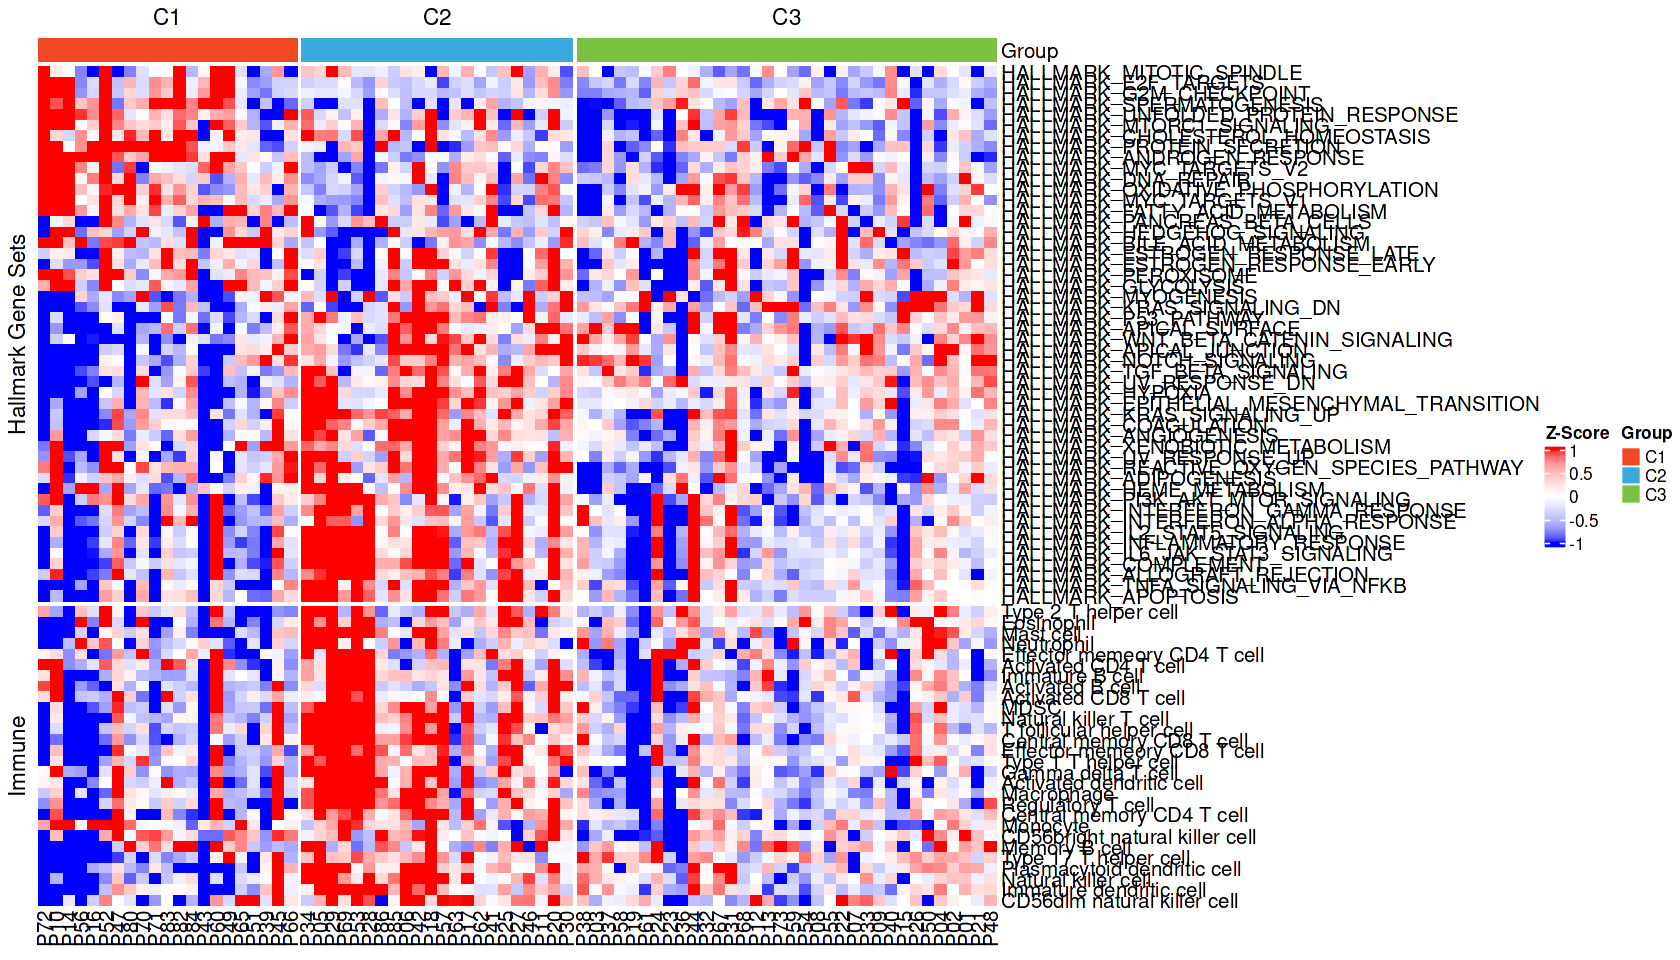

In [68]:
make.custom(14,8)
r = yplot_heatmap(mat = mat.hm.im
            , row_split = rowsplit
            , cluster_columns = FALSE
          , cluster_rows = TRUE
          , colData = colData
          , annotation_colors = COL_ANNO_3G
          , color = COL_HEATMAP_1_F
          , by_group = TRUE
          , show_row_dend = FALSE
          , show_column_dend = FALSE
          , cluster_column_slices=FALSE
        )
r$gg

In [69]:
r$gg %>% ysave('fig.S4A.rna_hm_im_heat',outputdir = OUTPUTROOT)
mat.hm.im %>% as.data.frame %>% ysave('fig.S4A.rna_hm_im_heat',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 08:35:16 ]  write 1 pdf at report_c3/fig.S4A.rna_hm_im_heat.pdf"
[1] "[ 2026-08-03 08:35:16 ]  write 1 xlsx at report_c3/fig.S4A.rna_hm_im_heat.xlsx"


## fig S4B

In [4]:
## dependecies: install.packages(c('vegan','ade4'))
# then install by downloaded pkg from github https://github.com/hannet91/ggcor.git
# cd ggcor && R CMD INSTALL .
library(ggcor)

gen_column_hcluster_dend = function(mat){
    row_dist <- dist(mat) # Calculate the distance matrix for rows
    row_hclust <- hclust(row_dist) # Perform hierarchical clustering

    # Step 3: Extract the dendrogram from the clustering object
    row_dendrogram <- as.dendrogram(row_hclust)
    row_dendrogram
}




Attaching package: ‘ggcor’


The following object is masked from ‘package:stats’:

    filter




In [5]:
p.hm = db.importing('export_c3/data_prt_hm_ssgsea.dfx', row.names = 1) %>% as.matrix
r.hm = db.importing('export_c3/data_rna_hm_ssgsea.dfx', row.names = 1) %>% as.matrix
rownames(p.hm) = rownames(p.hm) %>% str_sub(10)
rownames(r.hm) = rownames(r.hm) %>% str_sub(10)
p.hm = p.hm[rownames(r.hm), ]
r.hm

[1] "[ 2026-08-08 08:34:18 ]  read [ data_prt_hm_ssgsea.dfx ] as ' data_prt_hm_ssgsea ' from >  export_c3"
[1] "[ 2026-08-08 08:34:18 ]  read [ data_rna_hm_ssgsea.dfx ] as ' data_rna_hm_ssgsea ' from >  export_c3"


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
ADIPOGENESIS,0.5352774,0.5298981,0.5090610,0.5184800,0.5354779,0.5211951,0.5200553,0.5073797,0.5289627,0.5582152,0.5324584,0.5302997,0.5183914,0.51410397,0.5143569,⋯,0.5254624,0.5130609,0.4998273,0.4625052,0.5193511,0.5206493,0.4965634,0.4308143,0.5320755,0.5081452,0.5211257,0.5148786,0.5433077,0.5405400,0.5261268
ALLOGRAFT_REJECTION,0.2326303,0.2503244,0.2384866,0.2825841,0.3168723,0.2822995,0.2747259,0.2296043,0.2328125,0.3181382,0.2601588,0.2502184,0.2727498,0.04778801,0.1427947,⋯,0.2204546,0.2065525,0.2156567,0.2980156,0.2005738,0.1740938,0.2306263,0.2949878,0.2336081,0.2375681,0.2177265,0.2871917,0.2306788,0.2579551,0.2704492
ANDROGEN_RESPONSE,0.5890574,0.6126761,0.5148489,0.5700519,0.5536163,0.5677683,0.5944377,0.5979734,0.6070380,0.7073756,0.5689844,0.6164334,0.6692758,0.72334810,0.6111820,⋯,0.7484304,0.6312496,0.5363920,0.5940777,0.5749998,0.6039792,0.5328191,0.6213465,0.6321663,0.5836034,0.6735937,0.6847962,0.6602788,0.5895512,0.6068284
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
UV_RESPONSE_UP,0.3889393,0.3875211,0.3605759,0.3843370,0.4172113,0.3863432,0.3747113,0.3459818,0.3616664,0.4222272,0.3638295,0.3642286,0.3379974,0.3571061,0.3458448,⋯,0.3622854,0.3380766,0.3625837,0.3361088,0.3381536,0.3487323,0.3285762,0.3265504,0.3494795,0.3660530,0.3562501,0.3646824,0.3879374,0.4221292,0.3636105
WNT_BETA_CATENIN_SIGNALING,0.3893363,0.3750230,0.3840608,0.3899763,0.3702702,0.3878891,0.3967736,0.3442367,0.3888042,0.3496347,0.3902817,0.3824606,0.3632964,0.3645220,0.3480831,⋯,0.2465279,0.3680431,0.3721914,0.3372922,0.3465350,0.3492327,0.3059446,0.3326672,0.3170848,0.3717694,0.3257180,0.3370086,0.3585513,0.4001003,0.3304575
XENOBIOTIC_METABOLISM,0.3169911,0.3224968,0.3086505,0.3143726,0.3269857,0.3266780,0.2872466,0.3062376,0.3075108,0.3404812,0.3146023,0.3164913,0.3126442,0.2739694,0.2948532,⋯,0.2980902,0.2935568,0.2857357,0.2476658,0.2976162,0.2888410,0.2839699,0.2574565,0.3014670,0.3214422,0.3084378,0.2882905,0.3213407,0.3321165,0.3316892


In [6]:
stopifnot(all(rownames(p.hm)==rownames(r.hm)))
stopifnot(all(colnames(p.hm)==colnames(r.hm)))

In [7]:
r.rho = cor(r.hm %>% t, r.hm %>% t, method = 'spearman')
p.rho = cor(p.hm %>% t, p.hm %>% t, method = 'spearman')

rd = gen_column_hcluster_dend(r.rho)

r.order = rd %>% dendextend::get_leaves_attr('label')
r.order

pd = gen_column_hcluster_dend(p.rho)
p.order = pd %>% dendextend::get_leaves_attr('label')
p.order

Registered S3 method overwritten by 'dendextend':
  method     from 
  rev.hclust vegan



[1] "COMPLEMENT"                        "IL6_JAK_STAT3_SIGNALING"          
 [3] "INFLAMMATORY_RESPONSE"             "ALLOGRAFT_REJECTION"              
 [5] "INTERFERON_GAMMA_RESPONSE"         "TNFA_SIGNALING_VIA_NFKB"          
 [7] "APOPTOSIS"                         "IL2_STAT5_SIGNALING"              
 [9] "KRAS_SIGNALING_UP"                 "INTERFERON_ALPHA_RESPONSE"        
[11] "PI3K_AKT_MTOR_SIGNALING"           "APICAL_SURFACE"                   
[13] "KRAS_SIGNALING_DN"                 "APICAL_JUNCTION"                  
[15] "NOTCH_SIGNALING"                   "WNT_BETA_CATENIN_SIGNALING"       
[17] "MYOGENESIS"                        "UV_RESPONSE_DN"                   
[19] "EPITHELIAL_MESENCHYMAL_TRANSITION" "HYPOXIA"                          
[21] "TGF_BETA_SIGNALING"                "P53_PATHWAY"                      
[23] "ANGIOGENESIS"                      "COAGULATION"                      
[25] "HEME_METABOLISM"                   "ADIPOGENESIS"                     
[27] "REACTIVE_OXYGEN_SPECIES_PATHWAY"   "UV_RESPONSE_UP"                   
[29] "XENOBIOTIC_METABOLISM"             "CHOLESTEROL_HOMEOSTASIS"          
[31] "MTORC1_SIGNALING"                  "UNFOLDED_PROTEIN_RESPONSE"        
[33] "DNA_REPAIR"                        "MYC_TARGETS_V2"                   
[35] "FATTY_ACID_METABOLISM"             "OXIDATIVE_PHOSPHORYLATION"        
[37] "ESTROGEN_RESPONSE_EARLY"           "ESTROGEN_RESPONSE_LATE"           
[39] "GLYCOLYSIS"                        "PEROXISOME"                       
[41] "PANCREAS_BETA_CELLS"               "BILE_ACID_METABOLISM"             
[43] "HEDGEHOG_SIGNALING"                "MITOTIC_SPINDLE"                  
[45] "MYC_TARGETS_V1"                    "ANDROGEN_RESPONSE"                
[47] "PROTEIN_SECRETION"                 "SPERMATOGENESIS"                  
[49] "E2F_TARGETS"                       "G2M_CHECKPOINT"

[1] "MYC_TARGETS_V2"                    "MYC_TARGETS_V1"                   
 [3] "UNFOLDED_PROTEIN_RESPONSE"         "DNA_REPAIR"                       
 [5] "E2F_TARGETS"                       "G2M_CHECKPOINT"                   
 [7] "PANCREAS_BETA_CELLS"               "CHOLESTEROL_HOMEOSTASIS"          
 [9] "TGF_BETA_SIGNALING"                "ADIPOGENESIS"                     
[11] "GLYCOLYSIS"                        "ANDROGEN_RESPONSE"                
[13] "FATTY_ACID_METABOLISM"             "OXIDATIVE_PHOSPHORYLATION"        
[15] "PI3K_AKT_MTOR_SIGNALING"           "UV_RESPONSE_UP"                   
[17] "PEROXISOME"                        "MTORC1_SIGNALING"                 
[19] "PROTEIN_SECRETION"                 "NOTCH_SIGNALING"                  
[21] "ESTROGEN_RESPONSE_EARLY"           "ESTROGEN_RESPONSE_LATE"           
[23] "MITOTIC_SPINDLE"                   "SPERMATOGENESIS"                  
[25] "WNT_BETA_CATENIN_SIGNALING"        "REACTIVE_OXYGEN_SPECIES_PATHWAY"  
[27] "BILE_ACID_METABOLISM"              "XENOBIOTIC_METABOLISM"            
[29] "P53_PATHWAY"                       "ALLOGRAFT_REJECTION"              
[31] "INTERFERON_ALPHA_RESPONSE"         "INTERFERON_GAMMA_RESPONSE"        
[33] "HYPOXIA"                           "IL2_STAT5_SIGNALING"              
[35] "ANGIOGENESIS"                      "COAGULATION"                      
[37] "KRAS_SIGNALING_UP"                 "INFLAMMATORY_RESPONSE"            
[39] "TNFA_SIGNALING_VIA_NFKB"           "APOPTOSIS"                        
[41] "COMPLEMENT"                        "IL6_JAK_STAT3_SIGNALING"          
[43] "EPITHELIAL_MESENCHYMAL_TRANSITION" "APICAL_JUNCTION"                  
[45] "HEDGEHOG_SIGNALING"                "MYOGENESIS"                       
[47] "UV_RESPONSE_DN"                    "HEME_METABOLISM"                  
[49] "APICAL_SURFACE"                    "KRAS_SIGNALING_DN"

In [8]:
rho = cor(r.hm %>% t, p.hm %>% t, method = 'spearman')
rho

,ADIPOGENESIS,ALLOGRAFT_REJECTION,ANDROGEN_RESPONSE,ANGIOGENESIS,APICAL_JUNCTION,APICAL_SURFACE,APOPTOSIS,BILE_ACID_METABOLISM,CHOLESTEROL_HOMEOSTASIS,COAGULATION,COMPLEMENT,DNA_REPAIR,E2F_TARGETS,EPITHELIAL_MESENCHYMAL_TRANSITION,ESTROGEN_RESPONSE_EARLY,⋯,OXIDATIVE_PHOSPHORYLATION,P53_PATHWAY,PANCREAS_BETA_CELLS,PEROXISOME,PI3K_AKT_MTOR_SIGNALING,PROTEIN_SECRETION,REACTIVE_OXYGEN_SPECIES_PATHWAY,SPERMATOGENESIS,TGF_BETA_SIGNALING,TNFA_SIGNALING_VIA_NFKB,UNFOLDED_PROTEIN_RESPONSE,UV_RESPONSE_DN,UV_RESPONSE_UP,WNT_BETA_CATENIN_SIGNALING,XENOBIOTIC_METABOLISM
ADIPOGENESIS,0.2617010,0.04178499,0.03425633,0.25956885,0.2444361,0.07305062,0.2394358,0.29451389,0.1120902,0.3182509,0.2476815,-0.16675315,-0.25422897,0.2757960,0.12490212,⋯,0.1161659,0.13914807,0.007481485,0.175998868,0.114958253,0.01863295,0.3306099,0.06210670,-0.03138827,-0.06025756,-0.14094061,0.1206000,0.0843153,0.05154017,0.37014010
ALLOGRAFT_REJECTION,-0.1532431,0.82801076,-0.12012831,0.28496627,0.3025520,0.11278834,0.4815038,0.12816642,-0.2070758,0.4223312,0.6878721,-0.13820463,-0.15650738,0.2629275,-0.06027643,⋯,-0.1172414,0.43912449,-0.204490778,-0.007255059,0.229057974,0.07322043,0.2372470,-0.50880702,-0.06014435,0.57475353,-0.03540733,0.0788056,0.3208170,-0.29240058,0.25819142
ANDROGEN_RESPONSE,0.3294778,-0.25088919,0.60471720,-0.09157979,-0.3590264,-0.34306335,-0.2824190,0.09257984,0.4272183,-0.2554743,-0.3529883,0.06069154,0.07780556,-0.2561159,0.02259541,⋯,0.3269683,-0.09269305,0.384480400,0.439369782,0.006066324,0.45676683,-0.0755413,0.06516345,0.16809283,-0.31757158,0.41846314,-0.3722534,0.1550356,-0.18322562,-0.03036936
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
UV_RESPONSE_UP,0.02501061,0.3352517,-0.1577527,0.2960423,0.2236615,0.10239162,0.3343648,0.15531865,-0.06805038,0.3888580,0.4169159,-0.116807397,-0.12660031,0.3462522,0.02146328,⋯,-0.01984056,0.18605595,-0.08442851,0.07633379,0.07178641,0.03431294,0.1685834,-0.1500920,-0.02327468,0.11467522,-0.08061701,0.1355064,0.1632813,-0.06448417,0.27641870
WNT_BETA_CATENIN_SIGNALING,-0.24364357,0.0781452,-0.3134959,0.1113354,0.1336572,0.26400302,0.1339969,-0.09852352,-0.19479221,0.1844144,0.1792066,0.004481343,0.05467239,0.2353790,0.15156375,⋯,-0.19871692,-0.09852352,-0.10312751,-0.26570121,-0.08584367,-0.24277560,-0.0304637,0.1199585,0.02821831,0.04225671,-0.17131940,0.2580027,-0.1081277,0.20850984,0.00597198
XENOBIOTIC_METABOLISM,0.17875371,0.2403038,0.1163545,0.3829709,0.1718100,-0.02212369,0.3912354,0.21541582,-0.07461673,0.3528374,0.3873485,-0.072861927,-0.08359828,0.3085334,-0.04221897,⋯,0.01538752,0.30111798,0.04725695,0.13903486,0.19618850,0.19660361,0.2152649,-0.1849993,0.13786499,0.07480542,-0.01129299,0.1119392,0.2066418,-0.01425539,0.38265013


In [9]:
# data_ssgsea_hm_clusters.dfx is generated by 
# ../../ALLNEW_PLOTS/reGrouping_frm4to3_R.ipynb
hm_cluster = db.importing('export_c3/data_ssgsea_hm_clusters.dfx') %>% 
    mutate(ssGSEA.HM = str_sub(ssGSEA.HM,10)) %>% 
    column_to_rownames('ssGSEA.HM')
hm_cluster

[1] "[ 2026-08-08 08:34:35 ]  read [ data_ssgsea_hm_clusters.dfx ] as ' data_ssgsea_hm_clusters ' from >  export_c3"


,Group
,<chr>
PI3K_AKT_MTOR_SIGNALING,C1
UV_RESPONSE_UP,C1
BILE_ACID_METABOLISM,C1
⋮,⋮
ESTROGEN_RESPONSE_EARLY,C3
NOTCH_SIGNALING,C3
APICAL_SURFACE,C3


In [15]:
mantel02 = data.frame(spec = 'spec', env = rownames(rho), rho = rho %>% diag() ) %>% 
    mutate(`Rho's interval` = cut(rho, breaks = c(0, 0.25, 0.5,0.75,Inf), 
                        labels = c("0~0.25", "0.25~0.5","0.5~0.75", "0.75~1")),
           Enriched_in_Cluster = factor(hm_cluster[env,'Group'], levels = c('C1','C2','C3'))
          )
            
mantel02

,spec,env,rho,Rho's interval,Enriched_in_Cluster
,<chr>,<chr>,<dbl>,<fct>,<fct>
ADIPOGENESIS,spec,ADIPOGENESIS,0.2617010,0.25~0.5,C1
ALLOGRAFT_REJECTION,spec,ALLOGRAFT_REJECTION,0.8280108,0.75~1,C2
ANDROGEN_RESPONSE,spec,ANDROGEN_RESPONSE,0.6047172,0.5~0.75,C1
⋮,⋮,⋮,⋮,⋮,⋮
UV_RESPONSE_UP,spec,UV_RESPONSE_UP,0.1632813,0~0.25,C1
WNT_BETA_CATENIN_SIGNALING,spec,WNT_BETA_CATENIN_SIGNALING,0.2085098,0~0.25,C3
XENOBIOTIC_METABOLISM,spec,XENOBIOTIC_METABOLISM,0.3826501,0.25~0.5,C1


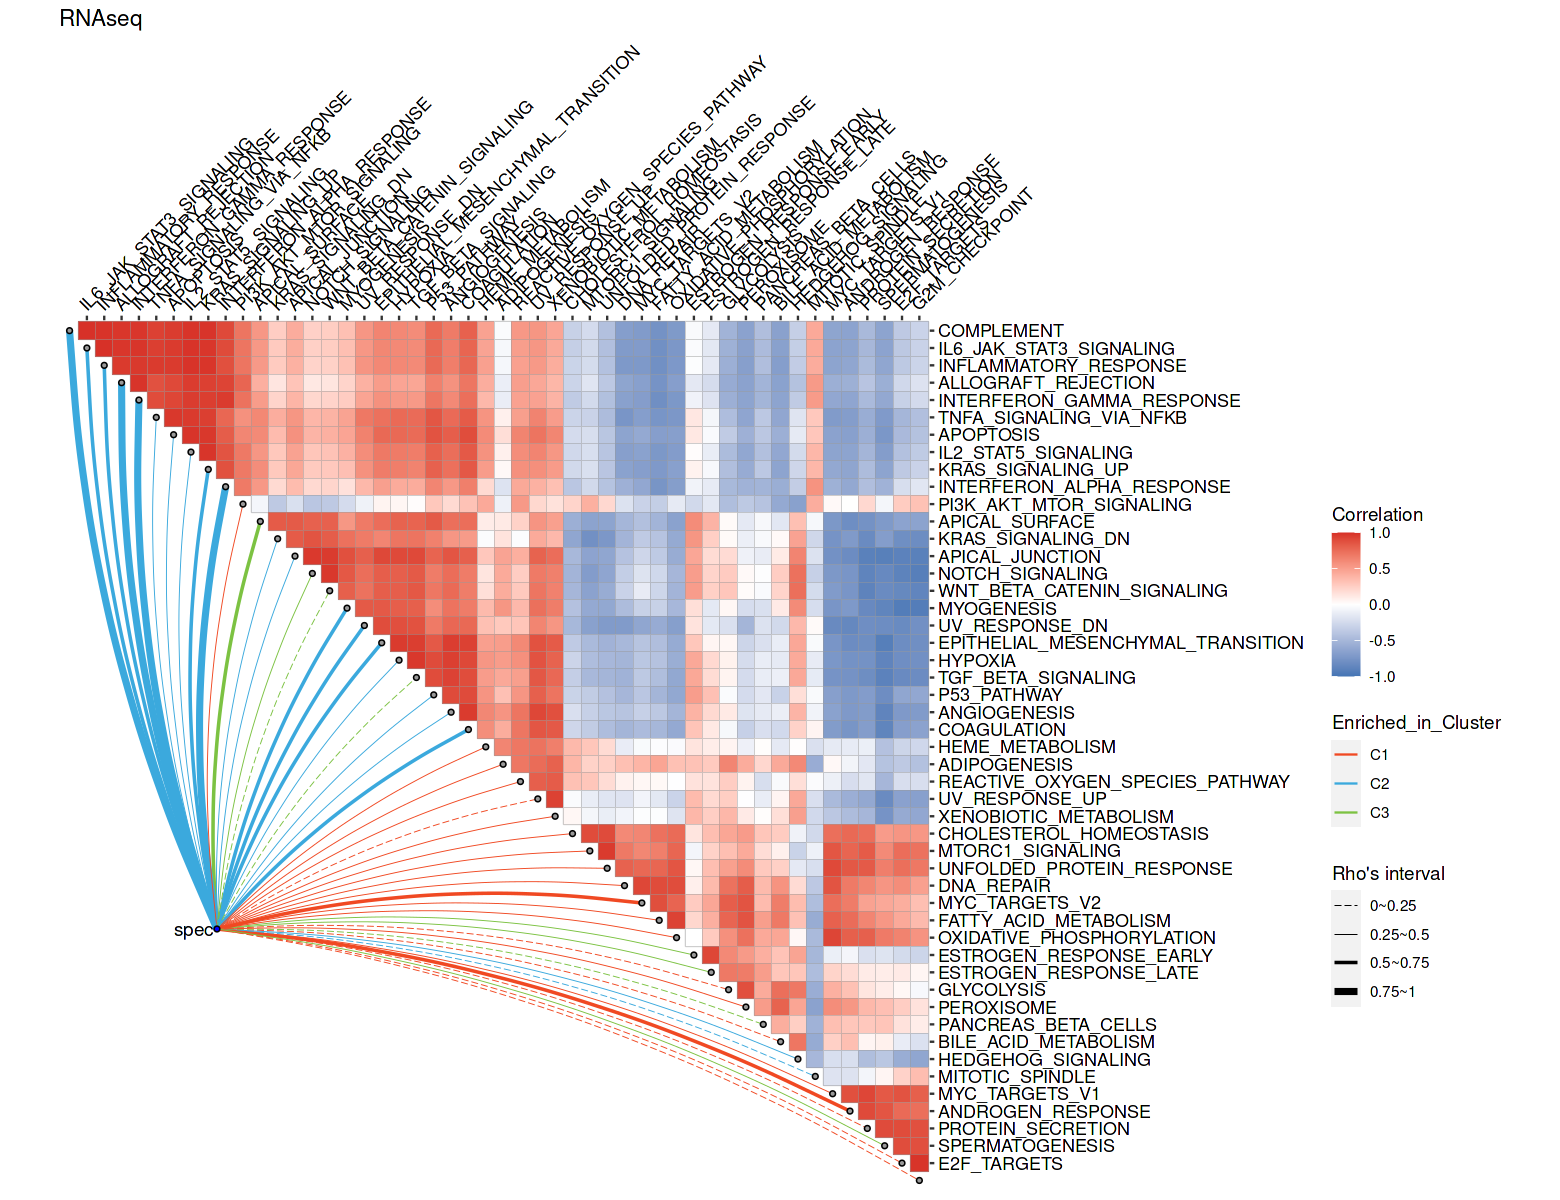

In [17]:
make.custom(13,10)
gg.r = quickcor(r.rho[r.order,r.order], type = "upper") + 
    ggcor::geom_color() +
    add_link(df = mantel02, mapping = aes(color = Enriched_in_Cluster, linewidth = `Rho's interval`, 
                                          linetype = `Rho's interval`),
               diag.label = FALSE) +
    scale_colour_manual(breaks = names(COL_GROUP3), values = COL_GROUP3) +  
    scale_linewidth_manual(breaks = c("0~0.25", "0.25~0.5","0.5~0.75", "0.75~1"), values = c(0.2,0.2,0.75,1.5))+
    # scale_color_manual(values = rainbow(50),breaks = lvls) +
#     scale_linetype_manual(values = c(1, 5, 5, 1), breaks = c('<-0.5','-0.5~0','0~0.5','>=0.5'))  + 
    scale_linetype_manual(breaks = c("0~0.25", "0.25~0.5","0.5~0.75", "0.75~1"), values = c(5,1,1,1)) +
#     remove_axis("x") +
#     guides(colour=FALSE) +
    scale_fill_gradient2(low = '#4575B4', high = '#D73027', mid = '#FFFFFF', midpoint = 0, 
                         limit = c(-1, 1), space = "Lab", name = "Correlation") +
    ggtitle('RNAseq')
gg.r    

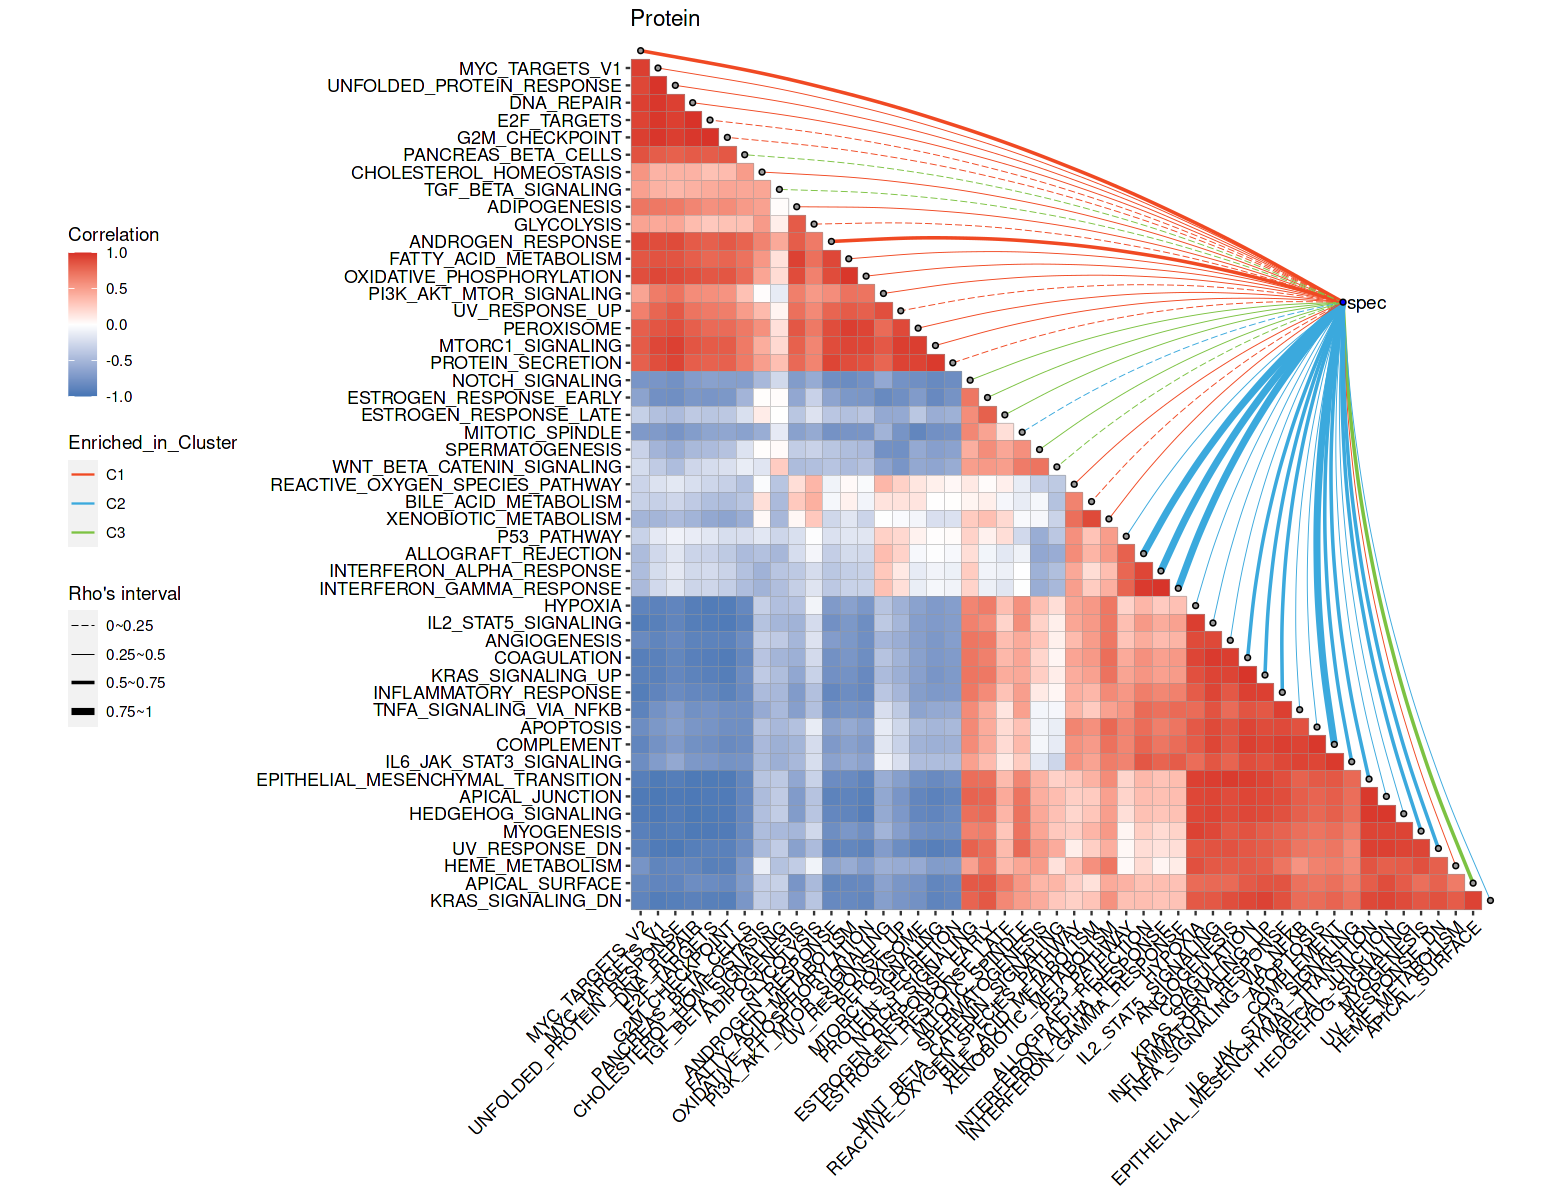

In [18]:
gg.p = quickcor(p.rho[p.order,p.order], type = "lower") + 
    ggcor::geom_color() +
    add_link(mantel02, mapping = aes(color = Enriched_in_Cluster, linewidth = `Rho's interval`, 
                                     linetype = `Rho's interval`),
               diag.label = FALSE) +
    scale_color_manual(breaks = names(COL_GROUP3), values = COL_GROUP3) +
    scale_linewidth_manual(breaks = c("0~0.25", "0.25~0.5","0.5~0.75", "0.75~1"), values = c(0.2,0.2,0.75,1.5))+
    scale_linetype_manual(breaks = c("0~0.25", "0.25~0.5","0.5~0.75", "0.75~1"), values = c(5,1,1,1)) +
#     scale_linetype_manual(values = c(1, 5, 5, 1), breaks = c('<-0.5','-0.5~0','0~0.5','>=0.5'))  + 
#     remove_axis("x") +
#     guides(colour=FALSE) +
#     scale_color_manual(values = rainbow(50),breaks = lvls) +
    scale_fill_gradient2(low = '#4575B4', high = '#D73027', mid = '#FFFFFF', midpoint = 0, 
                         limit = c(-1, 1), space = "Lab", name = "Correlation")+
    ggtitle("Protein")
gg.p    

In [19]:
make.custom(13,10)
gg.r %>% ysave('fig.S4B.rna',outputdir = OUTPUTROOT)
r.rho[r.order,r.order] %>% as.data.frame %>% ysave('fig.S4B.rna',outputdir = OUTPUTROOT)
gg.p %>% ysave('fig.S4B.prt',outputdir = OUTPUTROOT)
p.rho[p.order,p.order] %>% as.data.frame %>% ysave('fig.S4B.prt',outputdir = OUTPUTROOT)


[1] "[ 2026-08-08 08:41:09 ]  write 1 pdf at report_c3/fig.S4B.rna.pdf"
[1] "[ 2026-08-08 08:41:10 ]  write 1 xlsx at report_c3/fig.S4B.rna.xlsx"
[1] "[ 2026-08-08 08:41:10 ]  write 1 pdf at report_c3/fig.S4B.prt.pdf"
[1] "[ 2026-08-08 08:41:10 ]  write 1 xlsx at report_c3/fig.S4B.prt.xlsx"


In [21]:
mantel02 %>% ysave('fig.S4B.HM.rho.link_line.data', outputdir = OUTPUTROOT)
rho %>% as.data.frame %>% ysave('fig.S4B.HM.spearman.rho.data', table_title_lines = c("Spearman's Rho, row names are RNA HallMark items, column names are Protein HallMark items"), outputdir = OUTPUTROOT)

[1] "[ 2026-08-08 08:46:26 ]  write 1 xlsx at report_c3/fig.S4B.HM.rho.link_line.data.xlsx"
[1] "[ 2026-08-08 08:46:27 ]  write 1 xlsx at report_c3/fig.S4B.HM.spearman.rho.data.xlsx"


## fig S4C S4D

In [24]:
glx = db.importing('export_c3/wes_glx.dfx') %>% rename(tsb = Tumor_Sample_Barcode, Group = Clin_classification)
non.pcr = glx %>% filter(Group!='pCR') %>% pull(tsb)
non.pcr

[1] "[ 2026-08-30 12:40:28 ]  read [ wes_glx.dfx ] as ' wes_glx ' from >  export_c3"


[1] "P72" "P10" "P14" "P56" "P16" "P52" "P47" "P80" "P70" "P71" "P83" "P82"
[13] "P84" "P43" "P60" "P49" "P65" "P51" "P39" "P45" "P66" "P34" "P05" "P29"
[25] "P69" "P53" "P28" "P86" "P85" "P06" "P42" "P18" "P57" "P63" "P17" "P62"
[37] "P41" "P25" "P27" "P46" "P11" "P20" "P30" "P38" "P03" "P37" "P58" "P19"
[49] "P61" "P24" "P23" "P36" "P44" "P32" "P67" "P31" "P68" "P12" "P13" "P73"
[61] "P59" "P54" "P08" "P55" "P22" "P07" "P33" "P09" "P40" "P15" "P26" "P50"
[73] "P04" "P02" "P01" "P21" "P48"

In [25]:
matp = db.importing('export_by2_86_pCR_nonpCR/prt_x_7346.dfx',row.names=1) %>% as.matrix
matr = db.importing('export_by2_86_pCR_nonpCR/rna_count.dfx',row.names=1)%>% as.matrix

matp = matp[,non.pcr]
matr = matr[,non.pcr]
matp
matr

[1] "[ 2026-08-30 12:40:28 ]  read [ prt_x_7346.dfx ] as ' prt_x_7346 ' from >  export_by2_86_pCR_nonpCR"
[1] "[ 2026-08-30 12:40:29 ]  read [ rna_count.dfx ] as ' rna_count ' from >  export_by2_86_pCR_nonpCR"


,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
A1BG,-0.4503532,-0.1763565,-0.1674641,-0.09821636,-0.3900006,-0.02107001,-0.07319702,0.28097609,-0.2360201,-0.06241848,-0.06081656,0.254332178,0.19313675,-0.3165919,-0.08832465,⋯,0.09307132,-0.04438771,0.03916176,-0.2096906,0.003290244,-0.18867919,-0.21520441,0.10716068,0.06233078,0.1631934,0.002907455,0.2939069,0.287177300,0.46021669,0.1273033
A2M,-0.7344648,-0.3843764,-0.7912119,-0.85022267,-0.6991169,-0.44057899,0.19519318,0.47887702,0.2106339,-0.29646970,-0.26987836,-0.006584813,0.08291092,-0.6313362,-0.59934765,⋯,-0.29084987,-0.05774938,-0.37298434,-0.3369603,0.120576223,-0.25064389,-0.41658912,0.07218912,0.01744755,0.2449074,0.030336738,0.4094927,0.002229604,-0.16008838,0.3765419
NAT1,-0.4062785,0.9339046,0.1643513,0.80686294,-0.0804949,-0.23864566,0.54111059,-0.08672934,0.1205570,-0.10921825,0.14163022,-0.003910516,0.11802263,0.1567885,0.61641066,⋯,0.09370171,-0.11199446,-0.18808298,-0.3611383,-0.359137264,0.04050201,-0.07723629,0.17016346,-0.02011665,-0.1441538,0.290496090,0.1430298,-0.026871998,-0.03992174,-0.0830341
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
MMP24OS,0.01028101,-0.09939606,0.35936385,0.03099385,0.07781559,0.20887917,-0.05694813,-0.10943026,-0.03650823,-0.08644839,-0.006554967,0.07455987,0.04642637,-0.26783294,-0.3295093,⋯,0.0229764,0.05462692,-0.09081492,0.21506206,0.05979276,-0.09789900,-0.1122083,-0.39227925,-0.1583624,0.10856727,-0.76502545,-0.04444896,-0.621264397,-0.1526152,0.05014078
PIGBOS1,-0.10079324,0.08074380,0.02440433,-0.29328664,-0.19565603,0.15865734,0.08563127,1.11805949,-0.13716092,0.04422397,0.050621964,0.27900442,0.25783404,-0.73473431,-1.0147595,⋯,-0.0586082,0.17179920,-0.08974961,-0.09163530,0.20034071,0.23340032,-0.2667565,-0.06805847,0.1179062,0.64407899,0.12671735,-0.11042890,-0.049884599,-0.1064675,-0.06735307
C11orf98,0.48660996,0.32200949,0.18103901,-0.00950158,0.30577734,0.09663794,-0.01201577,0.04104325,0.09258186,0.27483949,0.150302465,0.07265562,0.26595657,-0.01194148,0.1482243,⋯,0.3175692,0.12676766,0.03862909,0.08974135,0.13361230,-0.02536341,-0.1628972,-0.05487164,-0.1363125,0.05306228,0.05945041,0.17542232,0.004816554,0.1327139,-0.00052700


,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
A1BG,3,2,8,7,4,7,8,0,17,4,3,4,5,4,13,⋯,11,14,17,22,10,15,10,8,11,8,10,12,7,13,13
A1CF,2,1,56,10,1027,32,22,0,2,2,15,1,0,4,6,⋯,27,10,685,1,3,0,4,16,7,21,6,8,17,5,9
A2M,31149,132159,14766,40855,103957,318602,153836,147314,384947,79687,44561,222087,125096,35851,78911,⋯,271831,216297,137560,119693,263121,138792,87035,106188,122937,236040,439178,217996,94068,276198,176080
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZYX,875,3733,2092,2311,2895,4270,2477,1122,4932,2178,2230,3670,2898,2977,2488,⋯,5620,4090,3458,4276,3364,5027,5482,2047,4467,4078,4387,3522,2364,3911,3635
ZZEF1,4281,7679,5691,7901,5864,10511,6443,5276,8844,6815,7512,10099,9762,9526,9236,⋯,15466,10757,10070,10649,7774,12599,9806,7261,10179,7987,9687,9942,8083,8271,8308
ZZZ3,3433,1713,2886,2461,3603,4453,2680,3469,5190,4911,4234,5574,4107,3874,2811,⋯,6360,4370,2821,3134,2398,4338,3878,3477,3577,3401,2962,3065,3029,2646,2669


In [26]:
res.deg = readRDS('export_c3/fig2_deg_dap.RDS')
anno_data = db.importing('export_c3/fig2_volcano_select_symbols.dfx')
anno_data

[1] "[ 2026-08-30 12:40:30 ]  read [ fig2_volcano_select_symbols.dfx ] as ' fig2_volcano_select_symbols ' from >  export_c3"


omic,Group,symbol
<chr>,<chr>,<chr>
RNAseq,C1,RAB3B
RNAseq,C1,AMACR
RNAseq,C1,KLK3
⋮,⋮,⋮
Protein,C3,GSTM3
Protein,C3,RAB34
Protein,C3,ACTG1


In [27]:
res.deg$Protein$C1$deg

symbol,Delta_Prt_Abundance,baseMean,t,pvalue,padj,B,stat,abs_Delta_PrtA,Delta_Ins,median_C1,mean_C1,median_Others,mean_Others,log2Delta,abs_log2Delta
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GOLPH3,0.5890346,-0.050853439,10.459526,1.646566e-16,1.224387e-12,26.92771,10.459526,0.5890346,TRUE,0.2925447,0.3775353,-0.20975247,-0.21149923,-0.7633388,0.7633388
CLCN3,0.3525533,0.009347626,8.546437,8.143314e-13,2.044425e-09,18.79960,8.546437,0.3525533,TRUE,0.1953581,0.2657501,-0.09845343,-0.08680329,-1.5036906,1.5036906
OSBP,0.1927679,0.001281042,8.543579,8.248082e-13,2.044425e-09,18.78736,8.543579,0.1927679,TRUE,0.1106091,0.1414759,-0.04697240,-0.05129202,-2.3743394,2.3743394
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ISCA1,-7.324135e-05,0.007732654,-0.0020848444,0.9983419,0.9986104,-6.502119,-0.0020848444,7.324135e-05,FALSE,-0.021015061,0.007679388,0.0004982225,0.007752629,-15.37546,15.37546
PITPNB,4.091202e-05,0.003706157,0.0015513364,0.9987662,0.9989005,-6.502120,0.0015513364,4.091202e-05,TRUE,-0.009704536,0.003735912,0.0002915000,0.003695000,-12.82641,12.82641
THEMIS2,2.175159e-05,-0.012800873,0.0004402692,0.9996498,0.9996498,-6.502122,0.0004402692,2.175159e-05,TRUE,-0.055048440,-0.012785054,-0.0141718550,-0.012806806,-13.04261,13.04261


In [33]:
make.custom(10,9)

grps = c("C1")
omics = list(RNAseq=matr
            ,Protein=matp
            )

for (grp in grps){
    # do DEG
    for (omic in names(omics)){
        if (omic == 'RNAseq'){
            t_logFC = 1
            title = 'DEG' # different Expressed Genes
            xlimits = 5
            ggtitle = paste(grp, omic, title, "FDR < 0.05",'abs(log2FoldC) >',t_logFC)
            gg_xlab = 'log2FoldChange'
            
            straw_len = xlimits / 10
            sel_genes = anno_data %>% filter(omic == !!omic, Group == !!grp) %>% pull("symbol")

            deg = res.deg[[omic]][[grp]]$deg %>% 
                filter(!is.na(log2FoldChange)) %>% 
                mutate(class = ifelse(abs_log2FC > !!t_logFC & padj < 0.05, ifelse(log2FoldChange>0, 'Up', 'Down'), 'Not Sig.')
                      , `-log10(FDR)` = -log10(padj)
                      , `-log10(FDR)` = ifelse(is.na(`-log10(FDR)`),Inf,`-log10(FDR)`)
                      , focused_gene = symbol %in% !!sel_genes
                  ) 
            df_anno = deg %>% filter(symbol %in% !!sel_genes)

            gg  = deg %>% ggplot(aes(x = log2FoldChange, `-log10(FDR)`)) +
                geom_point(aes(color = class, size = class), alpha = 0.4) +
                geom_vline(xintercept = t_logFC, linetype= 5, color = 'gray50') +
                geom_vline(xintercept = -t_logFC, linetype= 5, color = 'gray50') +    
                geom_hline(yintercept = -log10(0.05), linetype= 5, color = 'gray50') +
                scale_x_continuous(limits = c(-xlimits,xlimits)) +
                ggrepel::geom_text_repel(data  = df_anno, aes(label = symbol),max.iter = 10, nudge_x = straw_len, nudge_y = straw_len ) + 
    #             geom_segment(data = df_anno, aes(xend = log2FoldChange + straw_len, yend = `-log10(FDR)` + straw_len)) +
                scale_color_manual(values =  c('red','gray50','blue'), breaks = c('Up', 'Not Sig.','Down')) +
                scale_size_manual(values = c(3,1.5,3), breaks = c('Up', 'Not Sig.','Down')) +
                theme_bw(base_size = 18) +
                xlab(gg_xlab) +
                ggtitle(ggtitle)
            res.deg[[omic]][[grp]]$vol_deg = deg  
            res.deg[[omic]][[grp]]$gg.vol = gg
            res.deg[[omic]][[grp]]$selected = sel_genes
        }else{
            t_logFC = 0.35
            title = 'DAP' # different Abundance Proteins
            xlimits = 1
            ggtitle = paste(grp, omic, title, "FDR < 0.05",'log2FoldChange >',t_logFC)
            gg_xlab = 'log2FoldChange'
            
            straw_len = xlimits / 10
            sel_genes = anno_data %>% filter(omic == !!omic, Group == !!grp) %>% pull("symbol")

            deg = res.deg[[omic]][[grp]]$deg %>% 
                filter(!is.na(Delta_Prt_Abundance)) %>% 
                mutate(class = ifelse(abs_Delta_PrtA > !!t_logFC & padj < 0.05, ifelse(Delta_Prt_Abundance>0, 'Up', 'Down'), 'Not Sig.')
                      , `-log10(FDR)` = -log10(padj)
                      , `-log10(FDR)` = ifelse(is.na(`-log10(FDR)`),Inf,`-log10(FDR)`)
                      , focused_gene = symbol %in% !!sel_genes
                  ) 
            df_anno = deg %>% filter(symbol %in% !!sel_genes)

            gg  = deg %>% ggplot(aes(x = Delta_Prt_Abundance, `-log10(FDR)`)) +
                geom_point(aes(color = class, size = class), alpha = 0.4) +
                geom_vline(xintercept = t_logFC, linetype= 5, color = 'gray50') +
                geom_vline(xintercept = -t_logFC, linetype= 5, color = 'gray50') +    
                geom_hline(yintercept = -log10(0.05), linetype= 5, color = 'gray50') +
                scale_x_continuous(limits = c(-xlimits,xlimits)) +
                ggrepel::geom_text_repel(data  = df_anno, aes(label = symbol),max.iter = 10, nudge_x = straw_len, nudge_y = straw_len ) + 
    #             geom_segment(data = df_anno, aes(xend = Delta_Prt_Abundance + straw_len, yend = `-log10(FDR)` + straw_len)) +
                scale_color_manual(values =  c('red','gray50','blue'), breaks = c('Up', 'Not Sig.','Down')) +
                scale_size_manual(values = c(3,1.5,3), breaks = c('Up', 'Not Sig.','Down')) +
                theme_bw(base_size = 18) +
                xlab(gg_xlab) +
                ggtitle(ggtitle)
            res.deg[[omic]][[grp]]$vol_deg = deg  
            res.deg[[omic]][[grp]]$gg.vol = gg
            res.deg[[omic]][[grp]]$selected = sel_genes
        }
        
    }
}

[1] "[ 2026-08-30 12:40:32 ]  write 1 pdf at report_c3/fig.S4C.rna_deg_vol.pdf"
[1] "[ 2026-08-30 12:40:34 ]  write 1 xlsx at report_c3/fig.S4C.rna_deg_vol.xlsx"


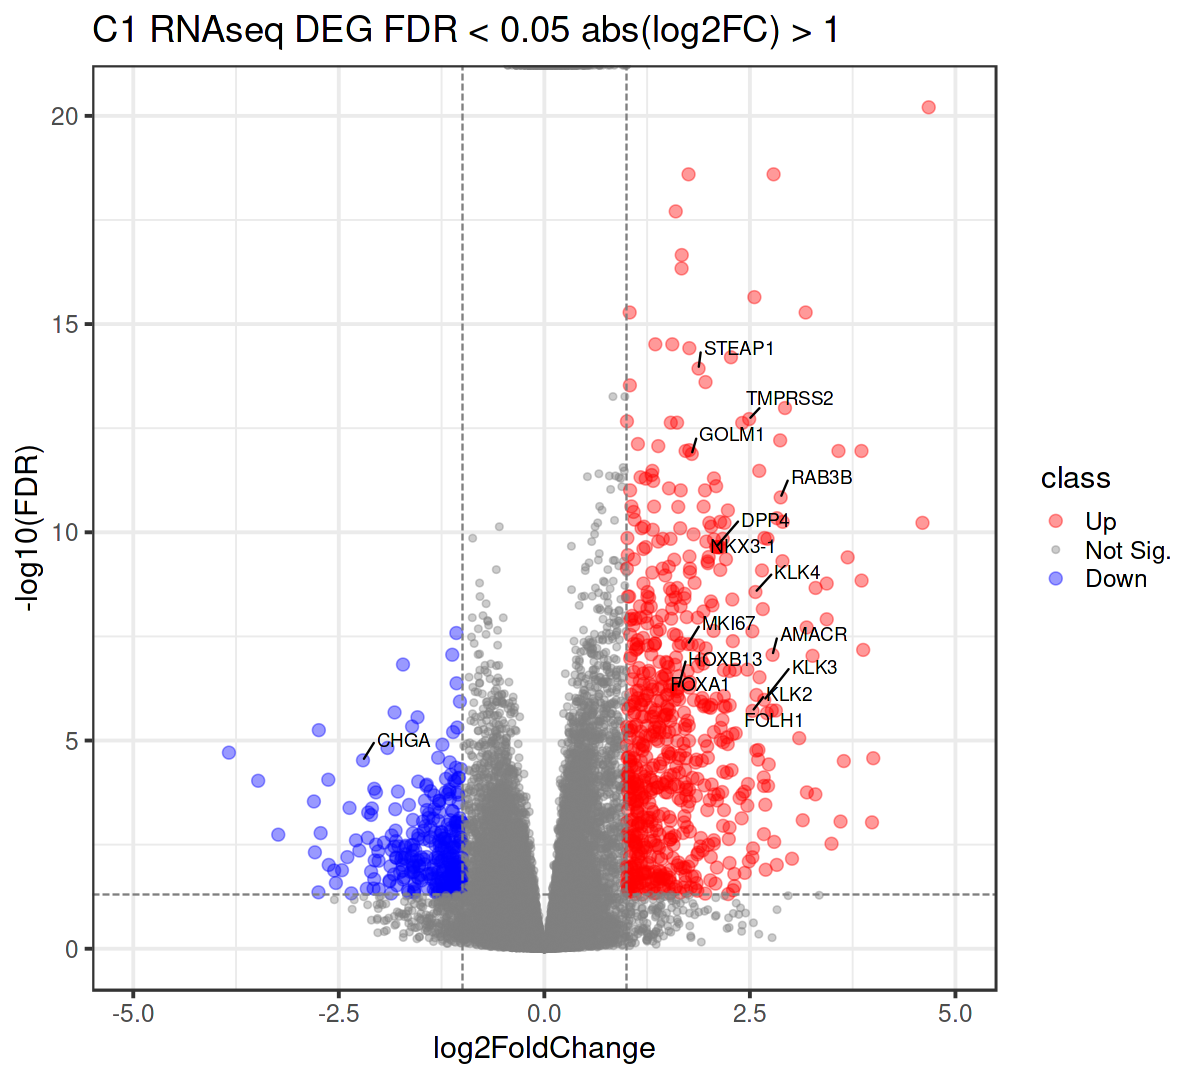

In [29]:
# different Expressed Genes
res.deg$RNA$C1$gg.vol
res.deg$RNA$C1$gg.vol %>% ysave('fig.S4C.rna_deg_vol')
res.deg$RNA$C1$vol_deg %>% ysave('fig.S4C.rna_deg_vol')

Warning message:
“Removed 2 rows containing missing values (`geom_text_repel()`).”
Warning message:
“Removed 2 rows containing missing values (`geom_text_repel()`).”


[1] "[ 2026-08-30 12:41:22 ]  write 1 pdf at report_c3/fig.S4D.prt_dap_vol.pdf"
[1] "[ 2026-08-30 12:41:23 ]  write 1 xlsx at report_c3/fig.S4D.prt_dap_vol.xlsx"


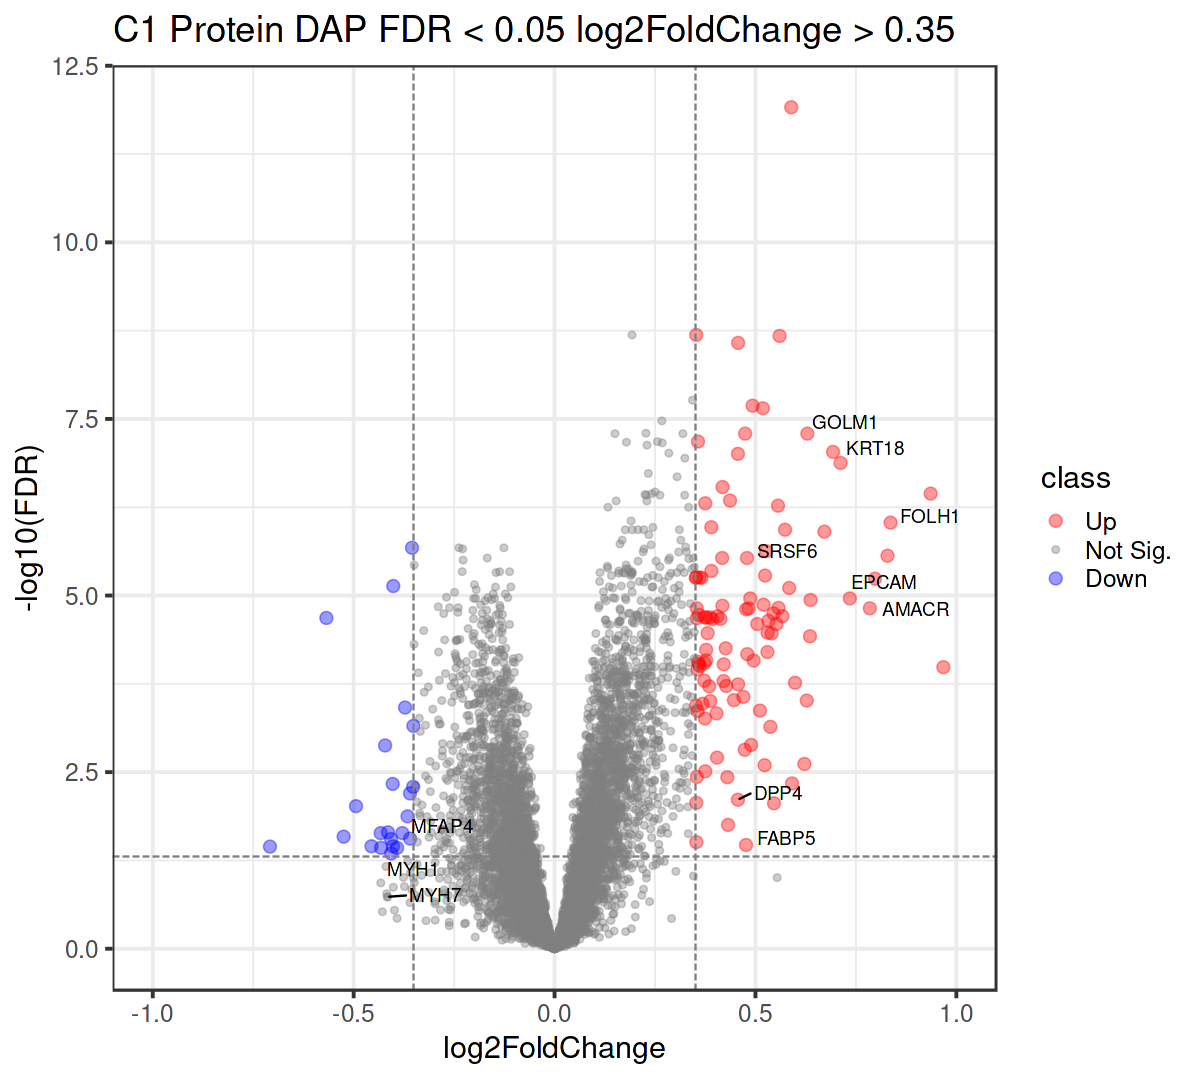

In [34]:
# different Abundance Proteins
res.deg$Protein$C1$gg.vol
res.deg$Protein$C1$gg.vol %>% ysave('fig.S4D.prt_dap_vol')
res.deg$Protein$C1$vol_deg %>% ysave('fig.S4D.prt_dap_vol')

## fig S4E C1 KEGG score heatmap

### gen data

In [50]:
res.deg = readRDS('export_c3/fig2_deg_dap.RDS')
res.deg %>% names

[1] "RNAseq"  "Protein"

In [51]:
kegg = yload_gmt('kegg')
sets = list(kegg=kegg)

In [52]:
res.gsea = list(RNAseq=list(), Protein=list())
grps = c("C1",'C2')
omic_names = c("RNAseq","Protein")

In [53]:
all_dfcs = list()
for (grp in grps){
    for (omic in omic_names){
        li = res.deg[[omic]][[grp]]$deg %>% drop_na() %>% arrange(desc(stat)) %>% pull(stat, name=symbol)
        dfc = list()
        for (j in names(sets)){
            gmt = sets[[j]]
            
            message(paste(" ======== Handling",omic, grp, j,'========'))
            
            gsea = clusterProfiler::GSEA(geneList = li, eps = 0,
                TERM2GENE = gmt, pAdjustMethod = "BH", pvalueCutoff = 1)
            
            df = gsea@result %>% 
                select( setSize, enrichmentScore, NES,  pvalue, p.adjust, qvalues, rank, leading_edge) %>% 
                rownames_to_column('ID') %>%
                mutate(Group=!!grp, set=!!j, type= omic)
            dfc[[length(dfc) + 1]] = df
            all_dfcs[[length(all_dfcs)+1]] = df
        }
        res.gsea[[omic]][[grp]] = dfc %>% reduce(.f = rbind)
    }
}
gsea.df = all_dfcs %>% reduce(.f = rbind) %>% mutate(`-log(FDR)` = -log10(p.adjust), `-log(p)` = -log10(pvalue))
message(' ======== GSEA DONE! ========')

 ======== Handling RNAseq C1 kegg ========



preparing geneSet collections...

GSEA analysis...

leading edge analysis...

done...

 ======== Handling Protein C1 kegg ========

preparing geneSet collections...

GSEA analysis...

leading edge analysis...

done...

 ======== Handling RNAseq C2 kegg ========

preparing geneSet collections...

GSEA analysis...

leading edge analysis...

done...

 ======== Handling Protein C2 kegg ========

preparing geneSet collections...

GSEA analysis...

leading edge analysis...

done...

 ======== GSEA DONE! ========



In [91]:
# save gsea.df & res.gsea
saveRDS(gsea.df, file = 'export_c3/fig2_c1_kegg_gsea_df.RDS')
saveRDS(res.gsea, file = 'export_c3/fig2_c1_kegg_gsea_res.RDS')

### load data

In [22]:
gsea.df = readRDS('export_c3/fig2_c1_kegg_gsea_df.RDS') %>%
    mutate(Grp = paste(type, Group ,sep='_'))

gsea.df


ID,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalues,rank,leading_edge,Group,set,type,-log(FDR),-log(p),Grp
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION,254,-0.3933109,-2.130919,5.005413e-13,9.260013e-11,5.479610e-11,5655,"tags=52%, list=31%, signal=37%",C1,kegg,RNAseq,10.03339,12.30056,RNAseq_C1
KEGG_FOCAL_ADHESION,199,-0.4209446,-2.249034,2.344726e-12,2.024509e-10,1.198002e-10,4997,"tags=54%, list=27%, signal=40%",C1,kegg,RNAseq,9.69368,11.62991,RNAseq_C1
KEGG_RIBOSOME,87,0.6107360,2.447037,3.282987e-12,2.024509e-10,1.198002e-10,5671,"tags=70%, list=31%, signal=49%",C1,kegg,RNAseq,9.69368,11.48373,RNAseq_C1
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
KEGG_INSULIN_SIGNALING_PATHWAY,95,0.1440500,0.6217857,0.9970414,0.9983498,0.6814892,2153,"tags=28%, list=29%, signal=20%",C2,kegg,Protein,0.0007172495,0.0012867994,Protein_C2
KEGG_GLYCOLYSIS_GLUCONEOGENESIS,49,-0.1519476,-0.6303597,0.9973333,0.9983498,0.6814892,1098,"tags=14%, list=15%, signal=12%",C2,kegg,Protein,0.0007172495,0.0011596655,Protein_C2
KEGG_VASOPRESSIN_REGULATED_WATER_REABSORPTION,28,0.1427435,0.4801783,0.9983498,0.9983498,0.6814892,1496,"tags=18%, list=20%, signal=14%",C2,kegg,Protein,0.0007172495,0.0007172495,Protein_C2


In [23]:
SEL = "-log(FDR)"
# SEL = "NES"
data = gsea.df %>% 
#     filter(qvalues < 0.2) %>% 
    filter(set == 'kegg') %>%
    pivot_wider(id_cols = "ID", names_from = "Grp" , values_from = !!SEL)
# drop some NA rows
mat = data[data %>% select(-ID) %>% is.na %>% apply(1, any) %>% not, ] %>% column_to_rownames("ID") %>% as.matrix
mat


,RNAseq_C1,Protein_C1,RNAseq_C2,Protein_C2
KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION,10.03339,2.04857,2.111073e+01,3.657708
KEGG_FOCAL_ADHESION,9.69368,12.56054,1.194941e+01,8.163551
KEGG_RIBOSOME,9.69368,21.81688,7.932322e-04,18.236924
⋮,⋮,⋮,⋮,⋮
KEGG_OLFACTORY_TRANSDUCTION,0.0012956495,0.9618212592,3.3198983,0.01391012
KEGG_LONG_TERM_POTENTIATION,0.0012956495,0.7835837748,0.2191904,0.08472624
KEGG_RIG_I_LIKE_RECEPTOR_SIGNALING_PATHWAY,0.0005665943,0.0007102119,0.2927193,0.28011770


### plot heatmap

In [24]:
sel = db.importing('external_data/fig.S3E.KEGG通路分析-挑选通路.xlsx') %>% 
    mutate(chosen = paste(set, ID, sep=':'))
sel

[1] "[ 2026-08-08 08:50:18 ]  read [ fig.S4E.KEGG通路分析-挑选通路.xlsx ] as ' fig.S4E.KEGG通路分析-挑选通路 ' from >  external_data"


,ID,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalues,rank,leading_edge,Group,set,type,-log(FDR),-log(p),Grp,chosen
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>
1,KEGG_RIBOSOME,87,0.6107360,2.470698,6.813189e-12,4.201467e-10,2.534028e-10,5671,"tags=70%, list=31%, signal=49%",C1,kegg,RNAseq,9.376599,11.166650,RNAseq_C1,kegg:KEGG_RIBOSOME
2,KEGG_OXIDATIVE_PHOSPHORYLATION,127,0.5191971,2.198014,1.556145e-09,5.077559e-08,3.062425e-08,5658,"tags=62%, list=31%, signal=43%",C1,kegg,RNAseq,7.294345,8.807950,RNAseq_C1,kegg:KEGG_OXIDATIVE_PHOSPHORYLATION
3,KEGG_SPLICEOSOME,123,0.5175566,2.178155,6.176382e-09,1.269590e-07,7.657269e-08,6217,"tags=65%, list=34%, signal=43%",C1,kegg,RNAseq,6.896337,8.209266,RNAseq_C1,kegg:KEGG_SPLICEOSOME
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
37,KEGG_TGF_BETA_SIGNALING_PATHWAY,84,0.3569283,1.542537,0.003893223,0.01214158,0.006945982,3256,"tags=35%, list=18%, signal=28%",C2,kegg,RNAseq,1.9157249,2.409691,RNAseq_C2,kegg:KEGG_TGF_BETA_SIGNALING_PATHWAY
38,KEGG_VEGF_SIGNALING_PATHWAY,74,0.3258742,1.381936,0.040465355,0.08970633,0.051319410,2041,"tags=20%, list=11%, signal=18%",C2,kegg,RNAseq,1.0471769,1.392917,RNAseq_C2,kegg:KEGG_VEGF_SIGNALING_PATHWAY
39,KEGG_NOTCH_SIGNALING_PATHWAY,47,0.3515611,1.343318,0.065645514,0.13420861,0.076778379,3606,"tags=26%, list=20%, signal=20%",C2,kegg,RNAseq,0.8722196,1.182795,RNAseq_C2,kegg:KEGG_NOTCH_SIGNALING_PATHWAY


In [25]:
chosen.df = gsea.df %>% mutate(chosen = paste(set, ID, sep=':')) %>% 
    filter(chosen %in% sel$chosen) %T>% View()


ID,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalues,rank,leading_edge,Group,set,type,-log(FDR),-log(p),Grp,chosen
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>
KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION,254,-0.3933109,-2.130919,5.005413e-13,9.260013e-11,5.479610e-11,5655,"tags=52%, list=31%, signal=37%",C1,kegg,RNAseq,10.03339,12.300560,RNAseq_C1,kegg:KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION
KEGG_RIBOSOME,87,0.6107360,2.447037,3.282987e-12,2.024509e-10,1.198002e-10,5671,"tags=70%, list=31%, signal=49%",C1,kegg,RNAseq,9.69368,11.483731,RNAseq_C1,kegg:KEGG_RIBOSOME
KEGG_OXIDATIVE_PHOSPHORYLATION,127,0.5191971,2.213483,7.583841e-10,2.338351e-08,1.383718e-08,5658,"tags=62%, list=31%, signal=43%",C1,kegg,RNAseq,7.63109,9.120111,RNAseq_C1,kegg:KEGG_OXIDATIVE_PHOSPHORYLATION
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
KEGG_GLYCOSAMINOGLYCAN_DEGRADATION,11,0.2176431,0.5608266,0.9566787,0.9974354,0.6808650,5820,"tags=100%, list=78%, signal=22%",C2,kegg,Protein,0.0011152102,0.019233895,Protein_C2,kegg:KEGG_GLYCOSAMINOGLYCAN_DEGRADATION
KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY,46,0.1723174,0.6563544,0.9611650,0.9974354,0.6808650,2625,"tags=43%, list=35%, signal=28%",C2,kegg,Protein,0.0011152102,0.017202030,Protein_C2,kegg:KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY
KEGG_GLYCOLYSIS_GLUCONEOGENESIS,49,-0.1519476,-0.6303597,0.9973333,0.9983498,0.6814892,1098,"tags=14%, list=15%, signal=12%",C2,kegg,Protein,0.0007172495,0.001159666,Protein_C2,kegg:KEGG_GLYCOLYSIS_GLUCONEOGENESIS


In [26]:
# SEL = "-log(FDR)"
SEL = "NES"
data = chosen.df %>% 
#     filter(qvalues < 0.2) %>% 
    filter(set == 'kegg') %>%
    pivot_wider(id_cols = "ID", names_from = "Grp" , values_from = !!SEL)
# drop some NA rows
mat = data %>% column_to_rownames("ID") %>% as.matrix
rownames(mat) = rownames(mat) %>% str_sub(6)

## filter C1 high part
c1n = colnames(mat) %>% stringr::str_ends('_C1')
mat1 = mat[apply(mat[,c1n], 1, min) > 0,]
mat1


,RNAseq_C1,Protein_C1,RNAseq_C2,Protein_C2
RIBOSOME,2.447037,3.192056,-0.5386616,-3.175790
OXIDATIVE_PHOSPHORYLATION,2.213483,2.106474,-1.3621243,-1.188114
SPLICEOSOME,2.198189,2.819033,-1.0003515,-3.445377
⋮,⋮,⋮,⋮,⋮
N_GLYCAN_BIOSYNTHESIS,1.587617,0.4510773,-1.197961,0.6427596
GLUTATHIONE_METABOLISM,1.604543,0.9781034,-1.039238,1.1015632
FATTY_ACID_METABOLISM,1.474018,1.6973409,-1.357361,-1.3026935


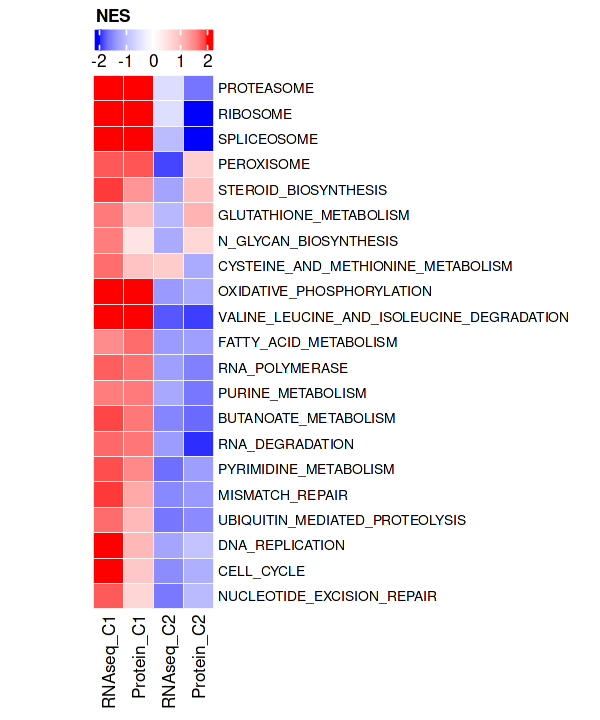

In [97]:
make.custom(5, 6)
plt = ComplexHeatmap::Heatmap(matrix =  mat1
              , column_title_gp = gpar(fontsize = 6)
                , show_row_dend = FALSE
#                 , column_title = paste('Protein',do,'GSEA')
                , rect_gp = gpar(col = COL_HEATMAP_BORDER, lwd=0.5)
                , name = SEL
                , column_names_gp = gpar(fontsize=10)
                , row_names_gp = gpar(fontsize=8)
        #         , top_annotation = HeatmapAnnotation(Group = anno_simple(x = colData$Group))
                , cluster_columns = FALSE
                , cluster_rows = TRUE
                , col = COL_HEATMAP_2_F
#                 , col = COL_HEATMAP_0_F
#                 , column_split = anno$Group
#                 , column_labels = anno$Cluster
               , heatmap_legend_param = list(direction = "horizontal")
              , width = unit(1, "inch")
            )
draw(plt, heatmap_legend_side = "top")

In [29]:
mat1 %>% as.data.frame %>% ysave('fig.S4E.KEGG.C1.data',outputdir = OUTPUTROOT)


[1] "[ 2026-08-08 08:52:43 ]  write 1 xlsx at report_c3/fig.S4E.KEGG.C1.data.xlsx"


## fig S4F
**Fig S4F — manually generated.** This panel was drawn manually with external tools; there is no plotting code in this repository. (EnrichmentMap network of GO terms enriched in C1)

In [98]:
cat(format(Sys.time(), "%Y-%m-%d %H:%M:%S"), "Job Done")

2026-08-03 08:53:25 Job Done